# 39 Endmodell: Monitoring-Modell gegen LSTM-Modell

Teil 8: Modellvergleich und Ergebnis

**Worum es geht**
- Im Projekt gibt es zwei fertige Ansätze: das Monitoring-Modell (Kennlinie und Netzvergleich) und das LSTM-Modell (neuronales Netz).
- Beide werden hier aus denselben Daten neu gelernt und nach denselben Regeln geprüft.
- Ergebnis: welches Modell welche Aufgabe der Aufgabenstellung übernimmt. Das ist die Grundlage des Dashboards in Notebook 40.
- Anlass: Notebook 38 hat Schwellen auf den Testfällen gewählt, und der LSTM-Encoder kannte dort die Teststationen. Eine frühere Prüfung (Audit, nicht im Abgabestand) hat das LSTM sauber neu gelernt, aber nicht mit dem ganzen Monitoring-Modell verglichen.

| | Monitoring-Modell | LSTM-Modell |
|---|---|---|
| Idee | Eigene Kennlinie je Station über der Außentemperatur. Ein CUSUM-Konto (Summe der Abweichungen, schlägt an, wenn sie zu groß wird) meldet, wenn die Station über Tage davon wegläuft. Dazu ein Netzvergleich mit den anderen Stationen im selben Winter. | Ein LSTM (neuronales Netz für Zeitreihen) sagt aus den letzten 7 Tagen Rücklauf und Durchfluss für heute voraus. Ein zweites LSTM fasst jeden Tag in 8 Zahlen zusammen. Daraus schätzt eine Regression die Fehlerart. |
| Notebooks | 21 Netzvergleich, 22 Tagesmonitor, 23 Alarme, 24 Bestwert, 25 Nachbarn, 26 Netzereignisse, 36 Netzkarte; Vorarbeit 13 bis 16 | 27 Modelldaten, 28 Einstufung, 29 LSTM, 30 Prognose-LSTM, 31 XGBoost |
| Code | `src/tagesmonitor.py`, `src/netzvergleich.py`, `src/alarmbewertung.py`, `src/stationsblatt.py` | `src/prognose_waechter.py`, `src/fehlerklassen.py` |

Dazu kommen XGBoost (Notebook 31) als dritter Kandidat für die Fehlerart und einfache Regeln ohne Lernen als Messlatte.

**Daten**
- liest: 93 Stundenreihen aus `data/processed/real_meters/`, `modell_stunden.parquet`, Begehungsprotokoll `data/raw/20252810_Ergebnis_Optimierung_FW[45].xlsx`, LSTM-Paket aus Notebook 30
- schreibt: Tabellen nach `outputs/finalvergleich/`, Modellpakete `normalmodell`, `prognose_lstm`, `fehlerklassen` nach `models/` (Versionsname `nb34_...`, stammt aus diesem Notebook)
- vorher ausführen: Notebook 00, 27, 30

**Code**
- Logik in `src/finalvergleich.py` (dazu `src/pruefstand.py`, `src/modellpaket.py`), Tests in `tests/test_finalvergleich.py`

Stand einer Aussage: belegt (Code oder Daten), nachgerechnet (hier ausgeführt), nur gespeichert (aus Datei übernommen), Deutung (nicht direkt gemessen), nicht prüfbar (Daten fehlen).

## 1 Ergebnisse im Überblick

- Keins der beiden Modelle ist allein besser. Sie können Verschiedenes, das Dashboard braucht beide.
- Alle Zahlen sind hier nachgerechnet: gleiche Daten aus Notebook 00, gleiche Zeitachse, Schwellen nur aus der Probezeit.

| Aufgabe im Dashboard | Modell | Grund | Urteil |
|---|---|---|---|
| Veränderung in der Heizperiode, Erfolgskontrolle nach Maßnahme | Monitoring-Modell (Kennlinie + CUSUM) | bemerkt Begehungen am deutlichsten: 18 von 43 gegen 24 % an Vergleichsstationen (p = 0,006); im Winter bei 10 % Fehlalarmen 47 % der eingebauten Rücklauffehler (Prognose-LSTM 33 %) | Pilot mit Einschränkungen |
| Veränderung an warmen Tagen, plötzlicher Dauerdurchfluss | LSTM-Modell (Prognose-LSTM + CUSUM, alle Stationen) | das Monitoring-Modell rechnet im Sommer nicht; bei 5 % Fehlalarmen 78 % der Dauerdurchflüsse 150 l/h (Wochenmittel 45 %) | Pilot mit Einschränkungen |
| Fehlerart Ventil (Reparatur nach Folie 5) | LSTM-Modell (Regression auf LSTM-Zahlen, nur begangene Stationen), Bestätigung durch das Fehlerbild „ventil“ des Monitoring-Modells | AUC 0,83 [0,64; 0,98], 8 von 11 bei 4 Fehlalarmen; andere Startwerte 0,84 und 0,90; mit Modellwahl im Lernteil 0,84, gleichauf mit der Sommernacht-Regel (0,85); Monitoring-Modell 4 von 4 richtig, aber nur 4 gefunden | Pilot |
| Dämmung | LSTM-Modell als Hinweis | AUC 0,79 [0,65; 0,90], andere Startwerte 0,79 und 0,77, mit Modellwahl 0,78; beste Einzelregel 0,61; Vorsprung +0,17 [−0,04; +0,38], knapp nicht gesichert | weitere Validierung nötig |
| Kapazitätsanpassung | Regel „Spitzenlast zum alten Vertrag“ | AUC 0,76, 5 von 9 bei 1 Fehlalarm; gelernte Modelle scheitern | Pilot mit Einschränkungen |
| Stationsleistung, Netzeffizienz, dauerhaft schlechter Betrieb | Monitoring-Modell (Netzvergleich, Potenzial) | nur der Vergleich mit anderen Stationen sieht dauerhaft schlechten Betrieb (Ventilfall 68956351: Rang 1 vor der Reparatur) | Pilot (beschreibend) |
| Regelungsoptimierung, Durchfluss, Sollwert, Filter, Regelhysterese | keins, nur als Symptom | nicht erkennbar (AUC um oder unter 0,5; Hysterese höchstens 15 %) | ungeeignet |
| XGBoost | nicht im Dashboard | nirgends verlässlich besser; Dämmung je nach Startwerten 0,74 bis 0,87 | ungeeignet |
| echte Frühwarnung | – | Beginn eines Fehlers nie bekannt | nicht prüfbar |

- Der Vorteil des Monitoring-Modells liegt an der Bauweise, nicht am Modelltyp: Ein LSTM mit fester Referenz ist praktisch gleich gut (Abschnitt 9). Bei Gleichstand bleibt die einfachere, erklärbare Kennlinie.
- Wichtigste Grenze: An 43 % der Testtage steht eines der Konten des Monitoring-Modells am Deckel, dort kann der Wächter nicht neu alarmieren. Nächster Schritt: Referenz nach jeder Begehung und zu jeder Heizperiode neu lernen.

## 2 Was gefordert ist

Aufgabenstellung des Projekts:
- Datenanalyse: Stationsleistung; Anomalien wie überhöhter Rücklauf, Dauerdurchfluss, dynamische Regelhysterese.
- Modellentwicklung: Anomalien erkennen, Fehlerarten an HAST klassifizieren.
- Visualisierung: Dashboard mit Netzeffizienz, Stationsleistung, Optimierungspotenzial.
- Empfehlungssystem: priorisierte Empfehlungen (Regelungsoptimierung, Reparatur, Kapazitätsanpassung).

Präsentation des Projektpartners (`notebooks/20260212_Anomaliedetektion.pdf`):

| Folie | Inhalt | Was wir daraus nehmen |
|---|---|---|
| 2 | leicht behebbare Fehler an Regelung und Ventilen führen zu hohem Rücklauf | Rücklauf ist das zentrale Symptom |
| 3 | +19,3 K Rücklauf durch Fehler; lange Ursachenliste | viele Ursachen, ein Symptom: warmer Rücklauf zeigt nicht eindeutig die Ursache |
| 4 | Regelhysterese, Dauerdurchfluss, ungedämmte Leitungen | eingebaute Fehler in Test B |
| 5 | drei Betriebsarten: effizient, mittel (Regelparameter optimieren), ineffizient (Regelventil tauschen) | drei Klassen in Test C |
| 6 | Optimierung von etwa 60 HAST: Netzverluste −13,4 %, Rendite 27 % | Beispiel des Partners, kein Ergebnis unserer Modelle |

| Aufgabe | gefordert? | geprüft an | Abschnitt |
|---|---|---|---|
| Symptom: Station gerade auffällig | ja | Netzvergleich, Kennzahlen | 11, 12 |
| Veränderung gegenüber eigenem Normalbetrieb | ja | Begehungen (Test A), eingebaute Fehler (Test B) | 7, 8 |
| Fehlerart | ja | Befunde der Begehungen | 11 |
| Warnung bei aktueller Auffälligkeit | Deutung von „Anomalieerkennung“ | wie Veränderung | 7, 8 |
| echte Frühwarnung vor künftigem Fehler | nicht ausdrücklich | nicht prüfbar: nur der Tag der Entdeckung ist bekannt | 16 |
| Effizienz und Potenzial | ja | Wirkung der Begehungen | 12 |
| Empfehlung und Reihenfolge | ja | Befunde unter den ersten 10 | 13 |

- Ein Wächter, der jede Station nur mit sich selbst vergleicht, sieht dauerhaft schlechten Betrieb nicht. Stabil ist nicht gleich gut. Dafür braucht es den Netzvergleich (Abschnitt 12).

## 3 Die Modelle in einfachen Worten

### 3.1 Monitoring-Modell: Kennlinie und CUSUM-Konto

- Aus den Zählerständen um Mitternacht entstehen je Tag Abkühlung (kWh je m³) und Tagesvolumen.
- Kennlinie: erwarteter Wert bei jeder Außentemperatur, gelernt auf Heiztagen der Referenzzeit. Sie nimmt das Wetter heraus.
- Jeden Heiztag: z = (gemessen − erwartet) / normale Streuung. Das Konto rechnet max(0, Konto + z − 0,5), getrennt je Richtung. Über h = 5 gibt es Alarm.
- Ein Alarm heißt: anders als in der Referenzzeit. Er sagt nicht, warum, und nicht, dass die Station vorher gut war.
- Nur Heiztage (Tagesmittel unter 15 °C). Im Sommer rechnet der Wächter nicht.

Netzvergleich (zweiter Teil):
- Je Kernwinter (Dezember bis Februar) fünf Kennzahlen je Station, z. B. Spreizung (Vorlauf minus Rücklauf) bei mittlerer Last, Anteil Stunden mit Rücklauf über 50 °C.
- Kennzahl im schlechtesten Zehntel des Winters gilt als „schlecht“. Ab zwei schlechten ist die Station auffällig.
- Aus der Kombination folgt ein Fehlerbild, z. B. „ventil“: Volumenstrom folgt der Leistung kaum, Spreizung klein.
- Potenzial = Abstand zum besten Viertel. Priorität „hoch“: auffällig und Wächter meldet im selben Winter Verschlechterung.

### 3.2 LSTM-Modell: Vorhersage des Tages und Fingerabdruck der Station

- Eingang: letzte 7 Tage × 24 Stunden Rücklauf, Durchfluss, Vorlauf, Außentemperatur, dazu heutiger Vorlauf und Außentemperatur.
- Ein LSTM (Encoder-Decoder, 64 Zustände) sagt Rücklauf und Durchfluss für heute Stunde für Stunde voraus. Gelernt auf allen Stationen gemeinsam.
- Abweichung (Rücklauf im Tagesmittel, Durchfluss nachts 0 bis 5 Uhr) wird als z-Wert normiert. Alarm über Schwelle an 2 Tagen in Folge oder über ein CUSUM-Konto.
- Weil das Netz die letzten 7 Tage sieht, gewöhnt es sich nach etwa einer Woche an eine bleibende Veränderung. Es rechnet in jeder Jahreszeit.

Fehlerart (zweiter Teil):
- Ein zweites LSTM (Notebook 29) übersetzt jeden Tag in 8 Zahlen (Embedding). Je Station Mittel über Winter 23/24 und Sommer 2024, nur Tage vor der Begehung.
- Eine logistische Regression schätzt daraus (und je nach Fassung aus 12 Kennzahlen wie dem Anteil Sommernächte mit Durchfluss) p(Ventil) und p(Dämmung).
- Klasse nach Folie 5: p(Ventil) ≥ 0,5 heißt „Reparatur (Ventil)“, sonst trennt ein K-Means mit zwei Gruppen „Regelungsoptimierung“ und „kein Handlungsbedarf“.
- Ein Embedding ist keine Diagnose. Erst die Regression verbindet es mit Befunden.

### 3.3 XGBoost

- Viele kleine Entscheidungsbäume nacheinander, jeder korrigiert die Fehler der vorigen. Gleiche Eingänge wie die Regression.
- Kann Wechselwirkungen finden, lernt bei 53 Stationen aber leicht Zufall mit. Erklärt wird er über Beiträge je Merkmal (Abschnitt 11).

### 3.4 Drei Gegenproben für einen fairen Vergleich

1. LSTM mit fester Referenz: sagt Abkühlung und Tagesvolumen nur aus dem Temperaturverlauf der letzten 7 Tage voraus, gelernt auf denselben Referenz-Heiztagen wie die Kennlinie des Monitoring-Modells, mit derselben Streuungsregel und demselben CUSUM. Einziger Unterschied: Gerade gegen neuronales Netz.
2. Nur begangene Stationen: Vorgabe für das Team. Gilt, wo mit Befunden gelernt wird (Fehlerart). Die Wächter lernen Normalverhalten ohne Befunde und lernen auf allen Stationen. Die andere Fassung läuft jeweils als Gegenprobe.
3. Ein eigenes Sommer-LSTM: Lohnt ein Modell nur für warme Tage, oder ist es mit einem Sommer Lerndaten überangepasst?

## 4 Daten: beide Modelle nutzen Notebook 00

- Die 93 Stundenreihen aus `data/processed/real_meters/` werden einmal geladen. Das Monitoring-Modell rechnet direkt darauf.
- Die Stundentabelle des LSTM wird aus denselben Reihen gebaut und mit `modell_stunden.parquet` aus Notebook 27 verglichen.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from src import finalvergleich as fv
from src import tagesmonitor as tm
from src import prognose_waechter as pw
from src import fehlerklassen as fk
from src import pruefstand as ps
from src import modellpaket as mp

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
plt.rcParams["figure.facecolor"] = "white"
print("PyTorch", torch.__version__, "| Grafikkarte:", torch.cuda.is_available())

PyTorch 2.11.0+cu128 | Grafikkarte: True


In [2]:
e = fv.lade_eingaben(ROOT)
pruefung = fv.gleiche_daten_pruefen(e["serien"], e["stunden"])
pruefung

,Prüfung,Wert
0,Zähler in den NB-00-Reihen,93.0
1,Zähler in der LSTM-Stundentabelle,93.0
2,größte Abweichung Rücklauf LSTM-Tabelle zu NB ...,0.0
3,gemessene Stunden in NB 27,1690145.0
4,gemessene Stunden hier,1690145.0
5,davon gleiche Zähler-Stunden,1690145.0
6,größte Abweichung Rücklauf zu NB 27 [K],0.0
7,größte Abweichung Durchfluss zu NB 27 [l/h],0.0


In [3]:
assert pruefung.loc[0, "Wert"] == pruefung.loc[1, "Wert"] == 93
assert pruefung.set_index("Prüfung").filter(like="Abweichung", axis=0)["Wert"].max() == 0.0
serien = e["serien"]
erste = min(s.index.min() for s in serien.values())
letzte = max(s.index.max() for s in serien.values())
print(f"93 HAST, Messungen von {erste:%d.%m.%Y} bis {letzte:%d.%m.%Y}")
print(f"gemessene Stunden mit Rücklauf und Durchfluss: {e['stunden'].dropna(subset=['ruecklauf', 'durchfluss']).shape[0]:,}".replace(",", "."))

93 HAST, Messungen von 01.11.2021 bis 20.07.2026
gemessene Stunden mit Rücklauf und Durchfluss: 1.690.145


- Beide Modelle sehen dieselben 93 Reihen, Stunde für Stunde gleich. Die LSTM-Tabelle ist identisch mit der aus Notebook 27 (nachgerechnet).

### 4.1 Labels aus den Begehungen

- Einzige Wahrheit sind die Begehungen (Protokoll der Übergabestationen). Notebook 27 macht daraus sechs Labels je Zähler.
- Laut Team und Projektpartner: Was im Protokoll steht, war der Fehler. Was nicht drinsteht, war es nicht.

In [4]:
lab = e["labels"]
termine = e["termine"]
n_termine = sum(len(v) for v in termine.values())
print(f"{len(lab)} begangene Zähler mit Zeitreihe, {n_termine} Begehungstermine mit Datum an {sum(1 for v in termine.values() if v)} Zählern")
d = pd.Series([pd.Timestamp(t) for v in termine.values() for t in v])
print("Begehungen je Monat:", d.dt.to_period("M").value_counts().sort_index().to_dict())
labeltabelle = pd.DataFrame({
    "Bedeutung": pd.Series(fv.ZIEL_TEXT),
    "Quelle": ["Kästchen Stellventil/Stellmotor oder Freitext (befundcodes)", "Kästchen oder Freitext",
               "Kästchen", "Kästchen", "Kästchen", "Vertrag neu kleiner als alt"],
    "Stationen mit Befund": [int(lab[z].sum()) for z in fv.ZIELE],
    "Stationen bekannt": [int(lab[z].notna().sum()) for z in fv.ZIELE],
})
labeltabelle

56 begangene Zähler mit Zeitreihe, 58 Begehungstermine mit Datum an 56 Zählern
Begehungen je Monat: {Period('2024-08', 'M'): 2, Period('2024-09', 'M'): 34, Period('2024-10', 'M'): 3, Period('2024-11', 'M'): 13, Period('2024-12', 'M'): 1, Period('2025-03', 'M'): 1, Period('2025-09', 'M'): 4}


,Bedeutung,Quelle,Stationen mit Befund,Stationen bekannt
ventil,Ventil getauscht / Ventilbefund,Kästchen Stellventil/Stellmotor oder Freitext ...,11,56
daemmung,Leitungen gedämmt,Kästchen oder Freitext,23,56
durchfluss,Durchfluss neu eingestellt,Kästchen,20,56
temperatur,Rücklauf-Sollwert gesenkt,Kästchen,36,56
filter,Filter gereinigt,Kästchen,26,56
ueberdimensioniert,Vertrag verkleinert,Vertrag neu kleiner als alt,9,37


| Aussage | Stand |
|---|---|
| Eintrag heißt: Fehler lag vor und wurde behoben. | belegt (Protokoll, Teamangabe) |
| Kein Eintrag heißt: Fehler lag nicht vor. Eine Meldung ohne Eintrag ist ein Fehlalarm. | Teamangabe, nur für begangene Stationen |
| Der Beginn eines Fehlers ist nie bekannt, nur das Datum der Begehung. | belegt |
| 37 HAST wurden nie begangen. Sie sind unbekannt, nicht gesund. | belegt |
| „Rücklauf-Sollwert gesenkt“ steht bei fast zwei Dritteln der begangenen Stationen. | belegt |
| Fehlerarten werden je Station gezählt, nie je Fenster. Tausende Tage aus 11 Ventilfällen sind 11 Fälle. | Spielregel |

## 5 Spielregeln

Die Regeln stehen vor jedem Testergebnis fest und gelten für beide Modelle.

1. Gleiche Daten: 93 Reihen aus Notebook 00.
2. Gleiche Zeitachse:
   - Lernen bis 31.01.2024 (Kennlinien und Netzgewichte),
   - Kalibrieren 08.02. bis 31.03.2024 (normale Schwankung des LSTM je Station),
   - Alarmlast einstellen April und Mai 2024,
   - Test ab 08.06.2024 bis Datenende, hier liegen alle Begehungen. 7 Tage Abstand (Eingabefenster des LSTM), damit Lernen und Test keinen Rohdatentag teilen.
3. Gleiche Alarmlast: Das Monitoring-Modell behält h = 5. Alle anderen Wächter bekommen so viele Alarme wie sie in der Einstellzeit. Wer öfter alarmiert, trifft sonst automatisch öfter.
4. Fehlerart je Station: fünffache Kreuzvalidierung über ganze Stationen (Zählertausch am selben Ort bleibt zusammen), LSTM-Encoder je Durchgang ohne Teststationen neu gelernt, feste Grenze p ≥ 0,5.
5. Nur Daten vor der Begehung. „Spitzenlast zum Anschlusswert“ bleibt draußen: Bei 7 von 9 verkleinerten Verträgen ist der Anschlusswert schon der neue.
6. Einfache Gegner laufen mit: Wochenmittel (Erwartung = Mittel der letzten 7 Tage), Sommernacht-Regel, Auslastung zum alten Vertrag.
7. Unsicherheit per Bootstrap über ganze Stationen, nie über Tage.
8. Zwei Fassungen je Wächter: „gemeinsam geschnitten“ ist der Hauptvergleich, „wie gebaut“ nur Gegenprobe.

**Warum diese Regeln**

- **AUC statt Accuracy oder F1:** Beim Ventil haben 20 % der Stationen einen Befund. Wer immer „kein Befund“ sagt, liegt zu 80 % richtig und findet nichts. Die AUC bewertet einen Score über alle Grenzen und hängt nicht an der Basisrate. Für den Betrieb kommt die Precision an der festen Grenze p ≥ 0,5 dazu (Test C) und die Trefferzahl unter den ersten 10 (Test E).
- **Kreuzvalidierung über ganze Stationen:** Das Label gehört zur Station, ihre Tage hängen eng zusammen. Ein Teil mit Tagen derselben Station im Lernen und im Test wäre geschönt.
- **Bootstrap über Stationen, nicht über Tage:** Die Station ist die unabhängige Einheit. Gepaart, also beide Modelle in jeder Ziehung auf denselben Stationen, damit ein Unterschied nicht nur von der Stichprobe kommt.
- **McNemar und Holm:** Zwei Wächter werden Fall für Fall verglichen (McNemar zählt nur die Begehungen, bei denen genau einer meldet). Bei vielen Gegenproben hebt die Holm-Korrektur die Schwelle, damit ein Zufallstreffer nicht als Ergebnis zählt.
- **Keine Suche über Größe oder Lernrate der Netze:** Die Netze lernen ohne Befunde, Early Stopping schaut nur auf den Vorhersagefehler der Probezeit. Eine Suche an 11 Ventilfällen würde auf die Antworten schauen. Gesucht wird nur die Regularisierung der Regression und Tiefe und Baumzahl von XGBoost, und zwar in der inneren Kreuzvalidierung (Abschnitt 19).


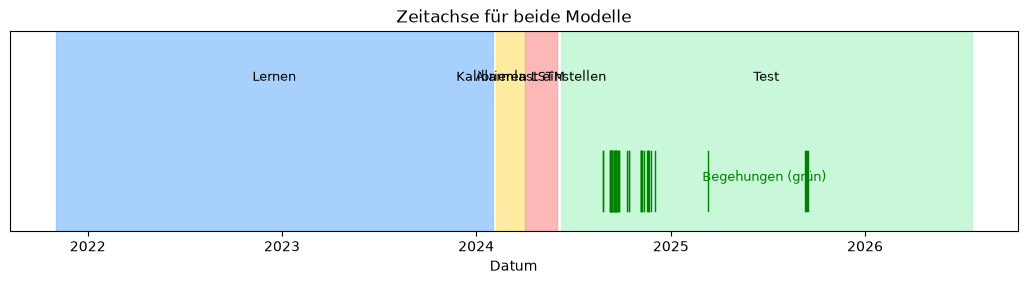

In [5]:
fig, ax = plt.subplots(figsize=(13, 2.6))
abschnitte = [("Lernen", erste, fv.LERN_ENDE, "#93C5FD"),
              ("Kalibrieren LSTM", fv.VAL_START, fv.WAHL_START, "#FDE68A"),
              ("Alarmlast einstellen", fv.WAHL_START, fv.VAL_ENDE, "#FCA5A5"),
              ("Test", fv.TEST_START, letzte, "#BBF7D0")]
for name, von, bis, farbe in abschnitte:
    ax.axvspan(von, bis, color=farbe, alpha=0.8)
    ax.text(von + (bis - von) / 2, 0.75, name, ha="center", fontsize=9)
for t in d:
    ax.plot([t, t], [0.1, 0.4], color="green", lw=1)
ax.text(pd.Timestamp("2025-03-01"), 0.25, "Begehungen (grün)", fontsize=9, color="green")
ax.set_ylim(0, 1)
ax.set_yticks([])
ax.set_title("Zeitachse für beide Modelle")
ax.set_xlabel("Datum")
fv.speichere(fig, "00_zeitachse")
plt.show()

## 6 Beide Modelle neu lernen

- `fv.waechter_bauen` lernt die Kennlinien des Monitoring-Modells und das Prognose-LSTM auf denselben Tagen (frühes Stoppen nur auf der Kalibrierzeit).
- Danach bekommen alle Wächter dieselbe Alarmlast. Dazu kommen die Gegenproben aus 3.4.
- Startwerte fest (Seed 0), ein neuer Lauf ergibt dieselben Gewichte.

In [6]:
w = fv.waechter_bauen(e)
print("Monitoring-Modell, Referenzstatus:", w["ref"]["status"].value_counts().to_dict())
print("LSTM: gelernt auf", len(w["lstm"]["lern_stationen"]), "Stationen,", w["lstm"]["lern_ziele"], "Lerntage und",
      w["lstm"]["val_ziele"], "Prüftage; kalibriert:", len(w["kal"]), "Stationen")
w = fv.nv_hinzufuegen(w, e)
w = fv.nur_begangene_hinzufuegen(w, e)
print("LSTM mit fester Referenz:", w["nv"]["stationen"], "Stationen,", w["nv"]["lern_tage"], "Referenz-Heiztage,",
      w["nv"]["pruef_tage"], "Prüftage")
print("Prognose-LSTM nur begangene:", len(w["beg"]["stationen"]), "Lernstationen")

Prognose-LSTM: 143 Runden, bester Validierungsfehler 0.1040, 28 s


Monitoring-Modell, Referenzstatus: {'ok': 86, 'zu wenige Referenztage': 6, 'keine Tage nach der Referenz': 1}
LSTM: gelernt auf 87 Stationen, 20510 Lerntage und 8599 Prüftage; kalibriert: 86 Stationen


LSTM mit fester Referenz: 65 Runden, bester Validierungsfehler 0.9982, 4 s


Prognose-LSTM: 104 Runden, bester Validierungsfehler 0.1072, 12 s


LSTM mit fester Referenz: 86 Stationen, 26546 Referenz-Heiztage, 4531 Prüftage
Prognose-LSTM nur begangene: 54 Lernstationen


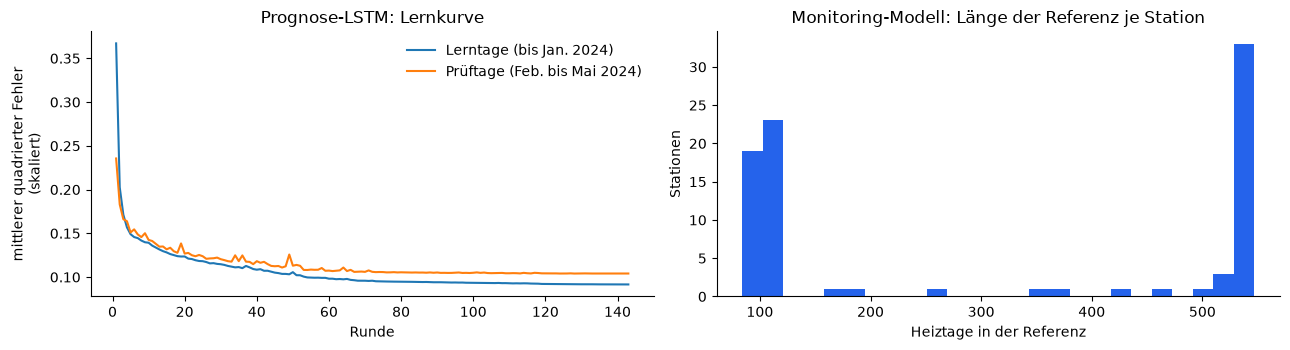

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
k = w["lstm"]["lernkurve"]
ax[0].plot(k["runde"], k["lernen"], label="Lerntage (bis Jan. 2024)")
ax[0].plot(k["runde"], k["validierung"], label="Prüftage (Feb. bis Mai 2024)")
ax[0].set_xlabel("Runde")
ax[0].set_ylabel("mittlerer quadrierter Fehler\n(skaliert)")
ax[0].set_title("Prognose-LSTM: Lernkurve")
ax[0].legend(frameon=False)
r = w["ref"]
ax[1].hist(r.loc[r["status"] == "ok", "ref_tage"], bins=25, color=fv.FARBE_MONITORING)
ax[1].set_xlabel("Heiztage in der Referenz")
ax[1].set_ylabel("Stationen")
ax[1].set_title("Monitoring-Modell: Länge der Referenz je Station")
for a in ax:
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fv.speichere(fig, "01_lernen")
plt.show()

- Das Monitoring-Modell gibt mit h = 5 im April und Mai 2024 eine bestimmte Zahl an Alarmen. Für jeden anderen Wächter wird je Regel der Wert gesucht, der am nächsten daran liegt.

In [8]:
print("Ziel:", w["ziel_alarme"], "Alarme auf", len(w["wahltage"]), "gemeinsamen Stationstagen")
pd.DataFrame([{"Wächter": fv.WAECHTER[k], "Regel": r, "gewählter Wert": v} for k, (r, v) in w["einstellung"].items()])

Ziel: 31 Alarme auf 2184 gemeinsamen Stationstagen


,Wächter,Regel,gewählter Wert
0,Monitoring-Modell (Kennlinie + CUSUM),cusum,5.00
1,LSTM-Modell + Schwelle,schwelle,2.75
2,LSTM-Modell + CUSUM,cusum,10.00
3,Wochenmittel + Schwelle (ohne Lernen),schwelle,3.00
4,Wochenmittel + CUSUM (ohne Lernen),cusum,10.00
5,LSTM mit fester Referenz (gebaut wie der Wächt...,cusum,15.00
6,"LSTM-Modell + CUSUM, nur begangene Stationen g...",cusum,10.00


In [9]:
last = fv.arbeitslast(w)
last.round(2)

,Wächter,Regel,Einstellung,Einstellzeit (Apr–Mai 2024),Test (ab Juni 2024)
0,Monitoring-Modell (Kennlinie + CUSUM),cusum,5.00,5.18,4.34
1,LSTM-Modell + Schwelle,schwelle,2.75,5.52,6.04
2,LSTM-Modell + CUSUM,cusum,10.00,5.52,3.40
3,Wochenmittel + Schwelle (ohne Lernen),schwelle,3.00,6.36,6.15
4,Wochenmittel + CUSUM (ohne Lernen),cusum,10.00,3.51,6.37
5,LSTM mit fester Referenz (gebaut wie der Wächt...,cusum,15.00,5.18,2.66
6,"LSTM-Modell + CUSUM, nur begangene Stationen g...",cusum,10.00,5.18,3.34


- In der Einstellzeit liegen alle Wächter bei ähnlich vielen Alarmen je Station und Jahr, im Test weichen sie ab (2,7 bis 6,4).
- Deshalb zeigen die Tests immer auch die Kontrollquote und Kurven über alle Einstellungen. So gewinnt kein Modell nur durch mehr Alarme.

## 7 Test A: Merkt das Modell, wenn sich eine Station verändert?

- Nach einer Begehung sollte die Station besser laufen. Meldet der Wächter das?
- Gezählt wird ein Alarm von 7 Tagen vor bis 60 Tage nach dem Termin (Prüfung aus Notebook 20, `pruefstand.trefferpruefung`). Dasselbe Fenster an Vergleichsstationen ohne Begehung ergibt die Kontrollquote.
- Getrennt nach Richtung wie in Notebook 23; nur Heiztage, die alle Wächter beobachten.
- Ein Alarm nach der Begehung zeigt die Wirkung der Maßnahme, keine Vorhersage des Fehlers.

In [10]:
A, einzel_A = fv.test_begehungen(w, termine)
A_besser = A[A["Richtung"] == "besser"]
A[["Wächter", "Richtung", "Fälle", "bemerkt", "Quote", "Kontrollquote", "Hebel", "p (einseitig)"]].round(3)

,Wächter,Richtung,Fälle,bemerkt,Quote,Kontrollquote,Hebel,p (einseitig)
0,Monitoring-Modell (Kennlinie + CUSUM),besser,43,18,0.419,0.237,1.766,0.006
1,Monitoring-Modell (Kennlinie + CUSUM),alle,43,23,0.535,0.459,1.166,0.198
2,Monitoring-Modell (Kennlinie + CUSUM),schlechter,43,10,0.233,0.275,0.845,0.784
3,LSTM-Modell + Schwelle,besser,43,10,0.233,0.256,0.908,0.694
4,LSTM-Modell + Schwelle,alle,43,19,0.442,0.472,0.936,0.708
5,LSTM-Modell + Schwelle,schlechter,43,11,0.256,0.310,0.824,0.826
6,LSTM-Modell + CUSUM,besser,43,10,0.233,0.263,0.884,0.729
7,LSTM-Modell + CUSUM,alle,43,17,0.395,0.435,0.909,0.749
8,LSTM-Modell + CUSUM,schlechter,43,9,0.209,0.242,0.865,0.746
9,Wochenmittel + Schwelle (ohne Lernen),besser,43,14,0.326,0.262,1.244,0.215


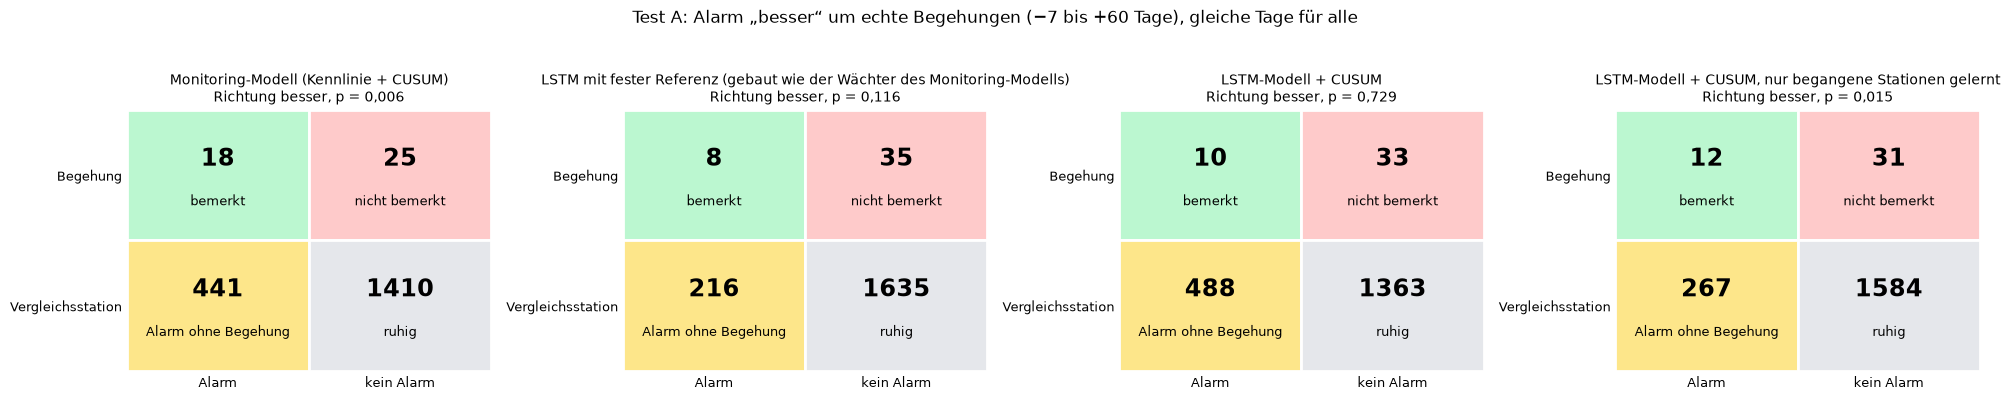

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(20, 3.8))
for ax, key in zip(axes, ["monitoring", "nv", "lstm_c", "lstm_beg"]):
    z = A_besser[A_besser["key"] == key].iloc[0]
    fv.zeichne_vierfeld(ax, z, f"{fv.WAECHTER[key]}\nRichtung besser, p = {z['p (einseitig)']:.3f}".replace(".", ","),
                        zeile_ja="Begehung", zeile_nein="Vergleichsstation",
                        spalte_ja="Alarm", spalte_nein="kein Alarm",
                        woerter=("bemerkt", "nicht bemerkt", "Alarm ohne Begehung", "ruhig"),
                        schluessel=("Begehung, Alarm", "Begehung, kein Alarm", "Kontrolle, Alarm", "Kontrolle, kein Alarm"))
fig.suptitle("Test A: Alarm „besser“ um echte Begehungen (−7 bis +60 Tage), gleiche Tage für alle", y=1.04)
fig.tight_layout()
fv.speichere(fig, "02_testA_konfusion")
plt.show()

- Vergleichsfenster überlappen sich und zeigen nur die Grundrate. Getestet wird über die Begehungen.
- Nächste Tabelle: dieselben Begehungen Fall für Fall, das Monitoring-Modell gegen die anderen (McNemar-Test).

In [12]:
a_mm = einzel_A[("monitoring", "besser")].set_index(["zaehler", "datum"])["treffer"]
zeilen = []
for key in ["nv", "lstm_s", "lstm_c", "lstm_beg", "wm_s", "wm_c"]:
    b = einzel_A[(key, "besser")].set_index(["zaehler", "datum"])["treffer"].reindex(a_mm.index)
    m = ps.mcnemar(a_mm, b)
    zeilen.append({"gegen": fv.WAECHTER[key], "nur Monitoring-Modell": m["nur A"], "nur der andere": m["nur B"],
                   "beide": m["beide"], "keiner": m["keiner"], "p (McNemar)": round(m["p (McNemar)"], 3)})
pd.DataFrame(zeilen)

,gegen,nur Monitoring-Modell,nur der andere,beide,keiner,p (McNemar)
0,LSTM mit fester Referenz (gebaut wie der Wächt...,12,2,6,23,0.013
1,LSTM-Modell + Schwelle,12,4,6,21,0.077
2,LSTM-Modell + CUSUM,15,7,3,18,0.134
3,"LSTM-Modell + CUSUM, nur begangene Stationen g...",12,6,6,19,0.238
4,Wochenmittel + Schwelle (ohne Lernen),10,6,8,19,0.454
5,Wochenmittel + CUSUM (ohne Lernen),10,7,8,18,0.629


- Jeder Punkt ist eine Einstellung. Rechts mehr Alarme im Test, oben mehr Vorsprung (Quote an Begehungen minus Kontrollquote). Der gewählte Punkt ist umrandet.

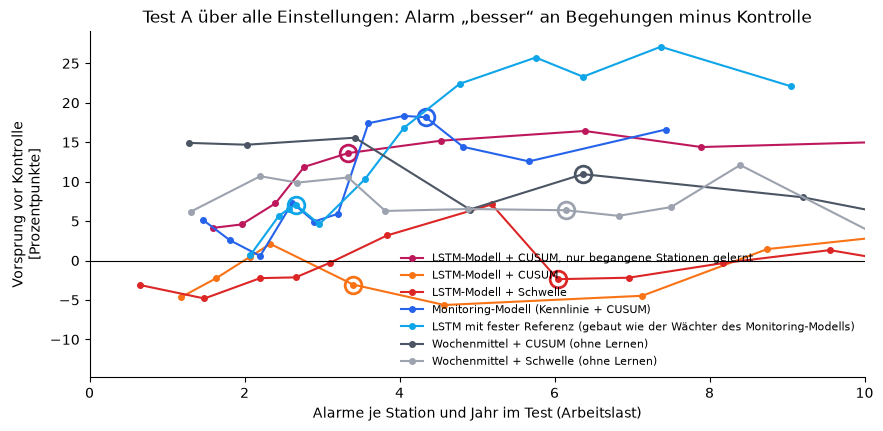

In [13]:
KA = fv.kurve_begehungen(w, termine)
fig, ax = plt.subplots(figsize=(10, 4.5))
farben = {"monitoring": fv.FARBE_MONITORING, "nv": "#0EA5E9", "lstm_s": fv.FARBE_LSTM, "lstm_c": "#F97316",
          "lstm_beg": "#BE185D", "wm_s": "#9CA3AF", "wm_c": "#4B5563"}
for key, g in KA.groupby("key"):
    g = g.sort_values("Arbeitslast")
    ax.plot(g["Arbeitslast"], 100 * g["Vorsprung"], "-o", ms=4, color=farben[key], label=fv.WAECHTER[key])
    s = g[g["gewählt"]]
    ax.plot(s["Arbeitslast"], 100 * s["Vorsprung"], "o", ms=12, mfc="none", mec=farben[key], mew=2)
ax.axhline(0, color="black", lw=0.8)
ax.set_xlim(0, 10)
ax.set_xlabel("Alarme je Station und Jahr im Test (Arbeitslast)")
ax.set_ylabel("Vorsprung vor Kontrolle\n[Prozentpunkte]")
ax.set_title("Test A über alle Einstellungen: Alarm „besser“ an Begehungen minus Kontrolle")
ax.legend(frameon=False, fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
fv.speichere(fig, "03_testA_kurve")
plt.show()

### 7.1 Gegenprobe: beide Wächter „wie gebaut“

- Die eigene Regel des Monitoring-Modells: Referenz ist das erste Jahr der Station, endet 14 Tage vor einer früheren Begehung.
- LSTM: Paket aus Notebook 30 (in Betrieb seit 24.10.2026), gelernt bis Juni 2024, Regel Schwelle z ≥ 4.
- Mit diesen Fassungen hat Notebook 38 gerechnet.

In [14]:
ref_g = fv.monitoring_referenz(w["mt"], termine, lern_ende=None)
mod_g, _ = tm.modelle(w["mt"], ref_g)
verl_g = fv.monitoring_verlauf(w["mt"], ref_g, mod_g)
al_g = fv.monitoring_alarme(verl_g)
#das Paket mit dem Code aus Notebook 30 (gebaut in Notebook 38, früher als Notebook 21), nicht die gerade aktive Version
nb30 = [v for v in mp.versionen("prognose_lstm")
        if any(k in mp.lade_paket("prognose_lstm", v, pruefen=False).meta.get("quelle", "")
               for k in ("30_prognose", "21_prognose"))]
alt_lstm = pw.lade(nb30[-1])
print("LSTM-Paket wie gebaut:", alt_lstm["paket"].version, "| Regel:", alt_lstm["parameter"].get("alarmregel"),
      alt_lstm["parameter"].get("schwelle"))
tab_alt = pw.anwenden(alt_lstm, e["stunden"])
tab_alt = tab_alt[tab_alt["status"] == "überwacht"]
al_alt = fv._alarmzeilen(tab_alt, tab_alt["alarm"].to_numpy())
al_alt["bewertung"] = np.where(al_alt["richtung"] > 0, "schlechter", "besser")
beob_g = fv.gemeinsame_tage(fv.monitoring_beobachtet(verl_g), fv.lstm_beobachtet(tab_alt))
A_g, einzel_g = fv.test_begehungen(w, termine, alarme={"monitoring (wie gebaut)": al_g, "lstm (Paket NB 30)": al_alt},
                                   tage=beob_g)
A_g[["Wächter", "Richtung", "Fälle", "bemerkt", "Quote", "Kontrollquote", "p (einseitig)"]].round(3)

LSTM-Paket wie gebaut: 2026-10-24_132552 | Regel: schwelle 4.0


,Wächter,Richtung,Fälle,bemerkt,Quote,Kontrollquote,p (einseitig)
0,monitoring (wie gebaut),besser,43,25,0.581,0.217,0.000
1,monitoring (wie gebaut),alle,43,29,0.674,0.486,0.010
2,monitoring (wie gebaut),schlechter,43,14,0.326,0.312,0.483
3,lstm (Paket NB 30),besser,43,7,0.163,0.078,0.048
4,lstm (Paket NB 30),alle,43,12,0.279,0.222,0.233
5,lstm (Paket NB 30),schlechter,43,9,0.209,0.177,0.349


In [15]:
t = einzel_g[("monitoring (wie gebaut)", "alle")].copy()
t["Referenz endet direkt vor dieser Begehung"] = [
    ref_g.at[z, "ende_grund"] == "vor Begehung" and 0 <= (dt - ref_g.at[z, "ref_ende"]).days <= 30
    for z, dt in zip(t["zaehler"], t["datum"])]
t.groupby("Referenz endet direkt vor dieser Begehung").agg(Begehungen=("treffer", "size"),
    bemerkt=("treffer", "sum"), Kontrollquote=("kontrollquote", "mean")).round(2)

,Begehungen,bemerkt,Kontrollquote
Referenz endet direkt vor dieser Begehung,,,
False,25,15,0.47
True,18,14,0.51


### 7.2 Gegenprobe: nur begangene Stationen als Vergleich

- Das Prognose-LSTM „nur begangene“ kennt kaum eine Vergleichsstation. Deshalb zählen hier für alle Wächter nur begangene Stationen ohne eigene Begehung im Fenster als Vergleich.

In [16]:
nur_beg = list(e["labels"].index)
gt_ = w["gemeinsam"][w["gemeinsam"]["datum"] >= fv.TEST_START]
zeilen = []
for key, a in w["alarme"].items():
    a = fv.nur_tage(a, gt_)
    for richt in ("besser", "alle"):
        aa = a if richt == "alle" else a[a["bewertung"] == richt]
        b = ps.bilanz(ps.trefferpruefung(aa, gt_, fv.begehungsfaelle(termine), termine, stationen=nur_beg))
        zeilen.append({"Wächter": fv.WAECHTER[key], "Richtung": richt, "Fälle": b["Fälle"], "bemerkt": b["Treffer"],
                       "Kontrollquote": b["Kontrollquote"], "p (einseitig)": b["p (einseitig)"]})
pd.DataFrame(zeilen).round(3)

,Wächter,Richtung,Fälle,bemerkt,Kontrollquote,p (einseitig)
0,Monitoring-Modell (Kennlinie + CUSUM),besser,43,18,0.337,0.167
1,Monitoring-Modell (Kennlinie + CUSUM),alle,43,23,0.529,0.531
2,LSTM-Modell + Schwelle,besser,43,10,0.301,0.875
3,LSTM-Modell + Schwelle,alle,43,19,0.450,0.602
4,LSTM-Modell + CUSUM,besser,43,10,0.448,0.999
5,LSTM-Modell + CUSUM,alle,43,17,0.505,0.945
6,Wochenmittel + Schwelle (ohne Lernen),besser,43,14,0.244,0.143
7,Wochenmittel + Schwelle (ohne Lernen),alle,43,22,0.555,0.766
8,Wochenmittel + CUSUM (ohne Lernen),besser,43,15,0.229,0.050
9,Wochenmittel + CUSUM (ohne Lernen),alle,43,18,0.389,0.402


### 7.3 Was Test A heißt

- Das Monitoring-Modell bemerkt die Wirkung der Begehungen am deutlichsten: 18 von 43 mit Meldung „besser“, Kontrolle 24 % (p = 0,006).
- Das Prognose-LSTM auf allen Stationen liegt auf Höhe der Kontrolle (10 von 43 gegen 26 %), bei jeder Einstellung.
- Fall für Fall ist der Vorsprung des Monitoring-Modells nicht gesichert: 12 zu 4 (p = 0,08) gegen Schwelle, 15 zu 7 (p = 0,13) gegen CUSUM.
- LSTM mit fester Referenz: bei h = 15 zu streng (8 von 43 gegen 12 %, 2,7 Alarme je Station und Jahr). Bei gleicher Arbeitslast fast gleichauf mit dem Monitoring-Modell (Abschnitt 9).
- Prognose-LSTM nur begangene: 12 von 43 gegen 14 % (p = 0,02), alle Richtungen 23 von 43 gegen 34 % (p = 0,007), auch mit begangenen Vergleichsstationen (23 von 43 gegen 33 %, p = 0,004).
  - Bei sieben Wächtern mit drei Richtungen sieht einer leicht zufällig gut aus. Im Sommer ist diese Fassung schwächer (Test B), sie bleibt Gegenprobe.
- Mit nur begangenen Vergleichsstationen schrumpft der Vorsprung des Monitoring-Modells (18 von 43 gegen 34 %, p = 0,17).
  - Deutung: Diese Stationen hatten selbst Maßnahmen, und das Monitoring-Modell meldet September-Begehungen oft erst im Oktober oder November, also im Fenster späterer Begehungen. Maßgeblich bleibt die Hauptprüfung.
- Beide Richtungen zusammen trennen beim Monitoring-Modell nicht (23 von 43 gegen 46 %). Verschlechterungen gibt es an Begehungen nicht öfter. Der Wächter zeigt die Wirkung einer Maßnahme, keine Vorhersage (passt zu Notebook 23).
- „Wie gebaut“ bemerkt das Monitoring-Modell mehr (25 von 43 gegen 22 %, p < 0,001). Ein Teil kommt aus der Referenzregel: Bei 18 Begehungen endet die Referenz kurz vorher (14 von 18 bemerkt, sonst 15 von 25). Für Erfolgskontrolle gewollt, für den Vergleich nicht fair.
- Fürs Dashboard: Der Tagesmonitor ist der Wächter für Heizperiode und Erfolgskontrolle.

## 8 Test B: Findet das Modell eingebaute Fehler?

- Bei echten Fehlern ist der Beginn nie bekannt. Deshalb wird ein Fehler mit bekanntem Beginn in echte Stundenwerte aus Notebook 00 geschrieben, 30 Tage lang.
- Je Station und Jahreszeit ein zufälliger Starttag mit genug Messwerten und ohne Begehung in der Nähe.
- Alle Spalten bleiben stimmig, auch Energie- und Volumenzähler. So lässt sich auch der Wächter des Monitoring-Modells prüfen (neu gegenüber Notebook 30 und 38).

| eingebauter Fehler | was passiert | Bezug |
|---|---|---|
| Dauerdurchfluss 50 / 150 l/h | zusätzliches Wasser mit Vorlauftemperatur, Rücklauf mischt sich warm | Folie 4 |
| Rücklauf +5 K | gleiche Leistung bei 5 K kleinerer Spreizung | Folie 2/3 |
| schleichend +5 K in 30 Tagen | wie oben, langsam ansteigend (z. B. Verschmutzung) | Folie 3 |
| Regelhysterese 6 h | 3 h 30 % mehr, 3 h 30 % weniger Durchfluss | Folie 4 |
| Fühler hängt | Rücklauffühler bleibt stehen | Folie 3 |

- Treffer: Alarm in 14 Tagen ab Fehlerbeginn (schleichend: 30 Tage). Dasselbe Fenster ohne Fehler ergibt die Fehlalarmquote. Hier ist die Wahrheit bekannt.

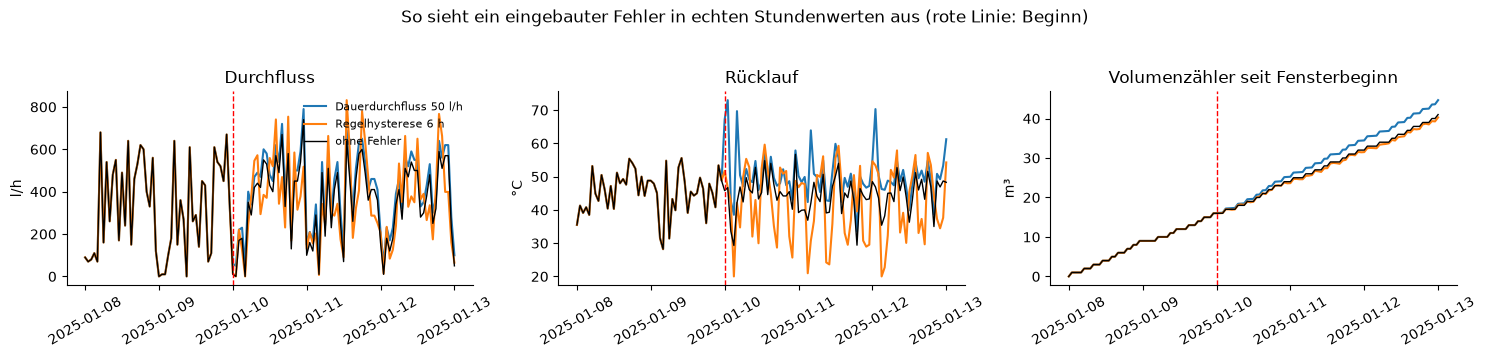

In [17]:
beispiel = e["serien"][next(m for m in w["kal"].index if e["serien"][m].loc["2025-01-05":"2025-01-15", "flow"].notna().sum() > 200)]
start = pd.Timestamp("2025-01-10")
fig, ax = plt.subplots(1, 3, figsize=(15, 3.4), sharex=True)
for art, (typ, staerke) in [("Dauerdurchfluss 50 l/h", fv.STOERUNGEN["Dauerdurchfluss 50 l/h"]),
                            ("Regelhysterese 6 h", fv.STOERUNGEN["Regelhysterese 6 h"])]:
    g = fv.stoerung_einrechnen(beispiel, start, typ, staerke, tage=5)
    fenster = g.loc[start - pd.Timedelta(days=2): start + pd.Timedelta(days=3)]
    ax[0].plot(fenster.index, fenster["flow"], label=art)
    ax[1].plot(fenster.index, fenster["rt"], label=art)
    ax[2].plot(fenster.index, fenster["volume"] - fenster["volume"].iloc[0], label=art)
roh = beispiel.loc[start - pd.Timedelta(days=2): start + pd.Timedelta(days=3)]
ax[0].plot(roh.index, roh["flow"], color="black", lw=1, label="ohne Fehler")
ax[1].plot(roh.index, roh["rt"], color="black", lw=1, label="ohne Fehler")
ax[2].plot(roh.index, roh["volume"] - roh["volume"].iloc[0], color="black", lw=1, label="ohne Fehler")
for a, t, y in zip(ax, ["Durchfluss", "Rücklauf", "Volumenzähler seit Fensterbeginn"], ["l/h", "°C", "m³"]):
    a.set_title(t)
    a.set_ylabel(y)
    a.axvline(start, color="red", ls="--", lw=1)
    a.spines[["top", "right"]].set_visible(False)
    a.tick_params(axis="x", labelrotation=30)
ax[0].legend(frameon=False, fontsize=8)
fig.suptitle("So sieht ein eingebauter Fehler in echten Stundenwerten aus (rote Linie: Beginn)", y=1.04)
fig.tight_layout()
plt.show()

In [18]:
ST = fv.stoerungen_rechnen(w, e)
SA = fv.stoerungen_auswerten(ST, w)
print(ST["faelle"].groupby("saison").size().rename("Stationen je Jahreszeit").to_dict())
SA.groupby(["saison", "Wächter"])["bewertbar"].mean().unstack().round(2)

25/157 Fälle, 12 s


50/157 Fälle, 23 s


75/157 Fälle, 34 s


100/157 Fälle, 45 s


125/157 Fälle, 57 s


150/157 Fälle, 68 s


{'Sommer': 78, 'Winter': 79}


Wächter,LSTM mit fester Referenz (gebaut wie der Wächter des Monitoring-Modells),LSTM-Modell + CUSUM,"LSTM-Modell + CUSUM, nur begangene Stationen gelernt",LSTM-Modell + Schwelle,Monitoring-Modell (Kennlinie + CUSUM),Wochenmittel + CUSUM (ohne Lernen),Wochenmittel + Schwelle (ohne Lernen)
saison,,,,,,,
Sommer,0.00,1.00,1.00,1.00,0.00,1.00,1.00
Winter,0.99,0.99,0.99,0.99,0.99,0.99,0.99


- Im Sommer kann der Wächter des Monitoring-Modells nicht bewerten, er rechnet nur an Heiztagen. Dort gibt es nur LSTM oder Wochenmittel.
- Nächste Tabellen: Trefferquote und Tage bis Alarm bei den gewählten Einstellungen. Zeile „ohne Fehler“ = Fehlalarmquote.

In [19]:
B = (SA[SA["bewertbar"]].groupby(["saison", "art", "Wächter"])
     .agg(Fälle=("alarm", "size"), Trefferquote=("alarm", "mean"), Tage_bis_Alarm=("tage_bis_alarm", "median"))
     .reset_index())
B.pivot_table(index=["saison", "art"], columns="Wächter", values="Trefferquote").round(2)

Wächter                              LSTM mit fester Referenz (gebaut wie der Wächter des Monitoring-Modells)  LSTM-Modell + CUSUM  LSTM-Modell + CUSUM, nur begangene Stationen gelernt  LSTM-Modell + Schwelle  \
saison art                                                                                                                                                                                                         
Sommer Dauerdurchfluss 150 l/h                                                     NaN                                        0.78                                               0.68                       0.81   
       Dauerdurchfluss 50 l/h                                                      NaN                                        0.44                                               0.45                       0.46   
       Fühler hängt                                                                NaN                                        0.36                                               0.32                       0.35   
       Regelhysterese 6 h                                                          NaN                                        0.08                                               0.08                       0.13   
       Rücklauf +5 K                                                               NaN                                        0.12                                               0.14                       0.26   
       ohne Fehler                                                                 NaN                                        0.04                                               0.05                       0.10   
       schleichend +5 K in 30 Tagen                                                NaN                                        0.18                                               0.17                       0.26   
Winter Dauerdurchfluss 150 l/h                                                    0.65                                        0.69                                               0.67                       0.73   
       Dauerdurchfluss 50 l/h                                                     0.42                                        0.46                                               0.44                       0.59   
       Fühler hängt                                                               0.37                                        0.27                                               0.33                       0.36   
       Regelhysterese 6 h                                                         0.05                                        0.10                                               0.12                       0.24   
       Rücklauf +5 K                                                              0.38                                        0.24                                               0.23                       0.42   
       ohne Fehler                                                                0.05                                        0.03                                               0.08                       0.18   
       schleichend +5 K in 30 Tagen                                               0.37                                        0.18                                               0.28                       0.44   

Wächter                              Monitoring-Modell (Kennlinie + CUSUM)  Wochenmittel + CUSUM (ohne Lernen)  Wochenmittel + Schwelle (ohne Lernen)  
saison art                                                                                                                                             
Sommer Dauerdurchfluss 150 l/h                                         NaN                                0.85                                   0.77  
       Dauerdurchfluss 50 l/h                                          NaN                                0.56                                   0.49  

In [20]:
B.pivot_table(index=["saison", "art"], columns="Wächter", values="Tage_bis_Alarm").round(1)

Wächter                              LSTM mit fester Referenz (gebaut wie der Wächter des Monitoring-Modells)  LSTM-Modell + CUSUM  LSTM-Modell + CUSUM, nur begangene Stationen gelernt  LSTM-Modell + Schwelle  \
saison art                                                                                                                                                                                                         
Sommer Dauerdurchfluss 150 l/h                                                     NaN                                         2.0                                                1.0                        1.0   
       Dauerdurchfluss 50 l/h                                                      NaN                                         3.5                                                4.0                        1.0   
       Fühler hängt                                                                NaN                                         4.0                                                4.0                        1.0   
       Regelhysterese 6 h                                                          NaN                                         9.0                                                7.0                        2.0   
       Rücklauf +5 K                                                               NaN                                         6.0                                                7.0                        4.0   
       ohne Fehler                                                                 NaN                                        11.0                                                7.5                        4.0   
       schleichend +5 K in 30 Tagen                                                NaN                                        22.0                                               18.0                       11.0   
Winter Dauerdurchfluss 150 l/h                                                     3.0                                         0.5                                                0.5                        1.0   
       Dauerdurchfluss 50 l/h                                                      6.0                                         1.0                                                2.5                        1.0   
       Fühler hängt                                                                4.0                                         3.0                                                7.0                        2.0   
       Regelhysterese 6 h                                                          4.5                                         9.0                                                8.0                        4.0   
       Rücklauf +5 K                                                               6.5                                         4.0                                                3.0                        2.0   
       ohne Fehler                                                                 4.5                                         7.5                                                4.0                        8.0   
       schleichend +5 K in 30 Tagen                                               22.0                                        23.0                                               18.0                       13.0   

Wächter                              Monitoring-Modell (Kennlinie + CUSUM)  Wochenmittel + CUSUM (ohne Lernen)  Wochenmittel + Schwelle (ohne Lernen)  
saison art                                                                                                                                             
Sommer Dauerdurchfluss 150 l/h                                         NaN                                 1.0                                    1.0  
       Dauerdurchfluss 50 l/h                                          NaN                                 2.0                                    1.0  

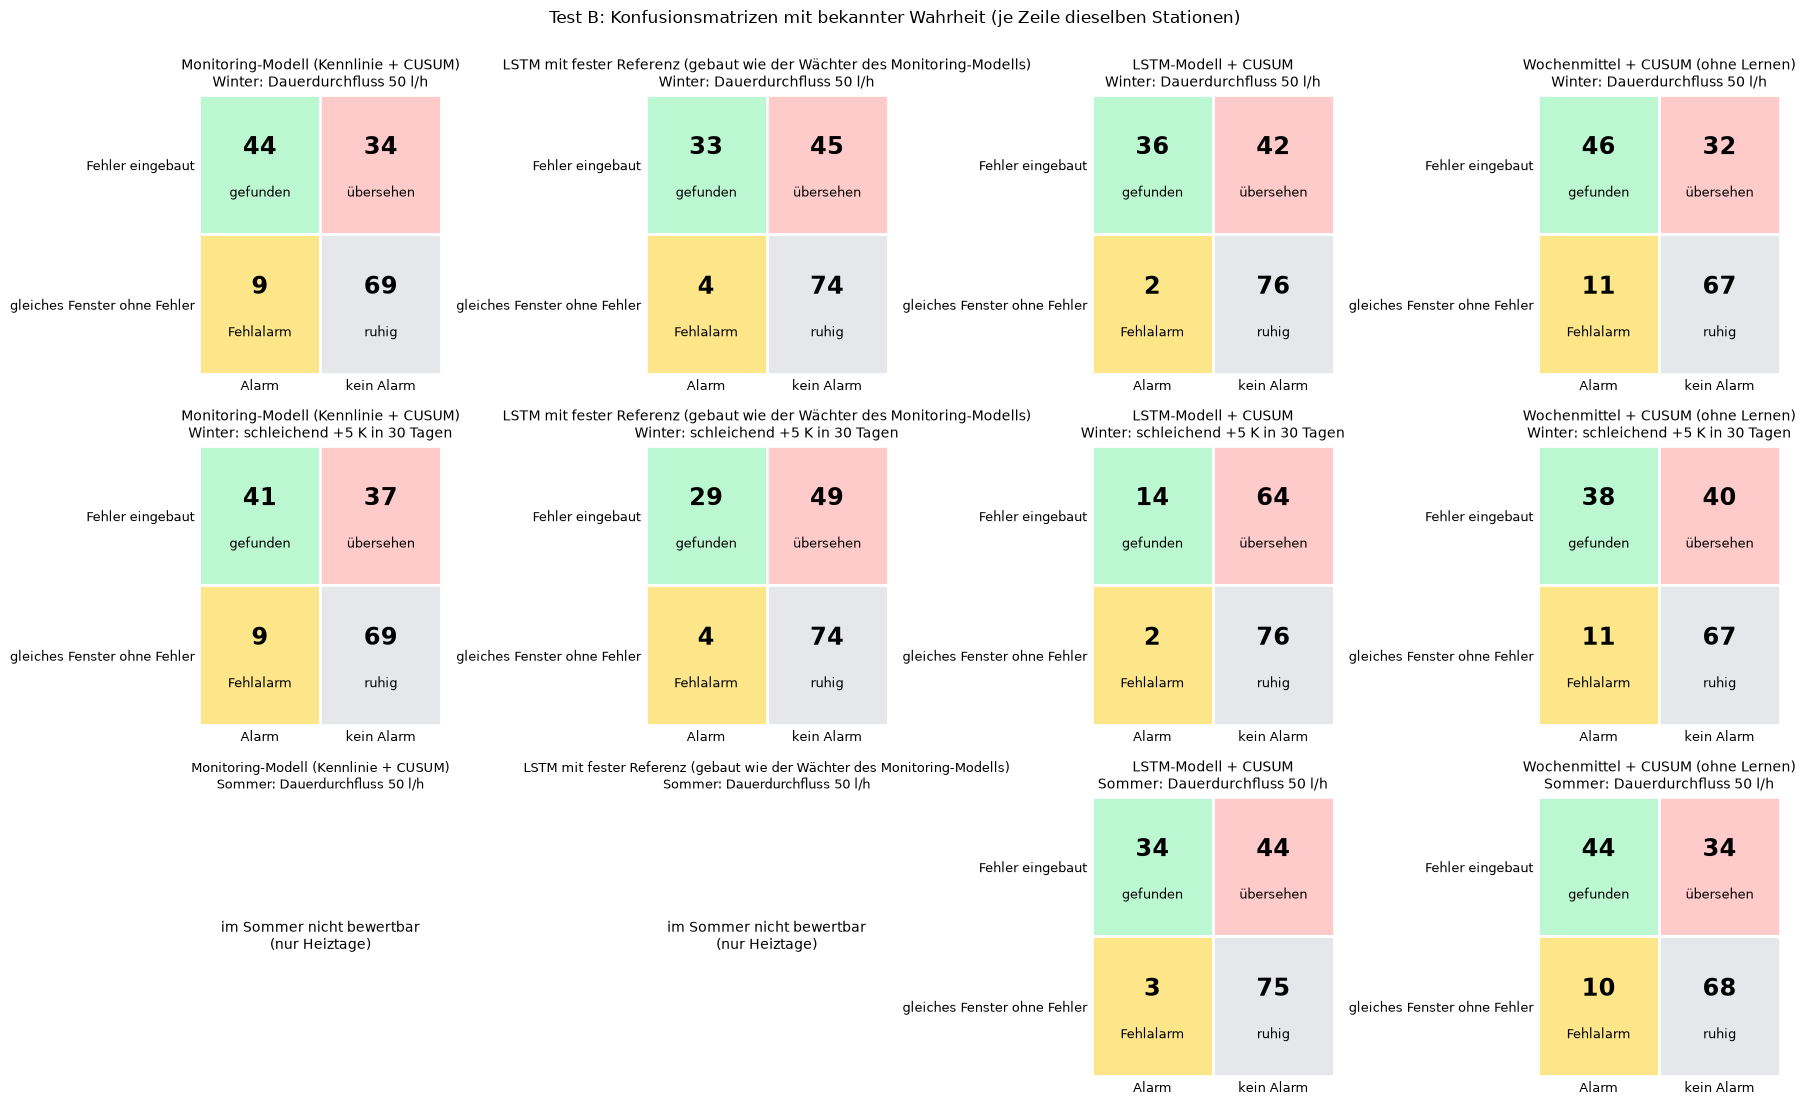

In [21]:
def vierfeld_stoerung(sa, key, saison, art):
    t = sa[(sa["key"] == key) & (sa["saison"] == saison) & sa["bewertbar"]]
    mit = t[t["art"] == art].set_index("zaehler")["alarm"]
    ohne = t[t["art"] == "ohne Fehler"].set_index("zaehler")["alarm"].reindex(mit.index).dropna().astype(bool)
    mit = mit.reindex(ohne.index)
    return {"gefunden": int(mit.sum()), "übersehen": int((~mit).sum()),
            "Fehlalarm": int(ohne.sum()), "ruhig": int((~ohne).sum())}

faelle_bild = [("Winter", "Dauerdurchfluss 50 l/h"), ("Winter", "schleichend +5 K in 30 Tagen"),
               ("Sommer", "Dauerdurchfluss 50 l/h")]
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for i, (saison, art) in enumerate(faelle_bild):
    for j, key in enumerate(["monitoring", "nv", "lstm_c", "wm_c"]):
        ax = axes[i, j]
        if saison == "Sommer" and key in ("monitoring", "nv"):
            ax.text(0.5, 0.5, "im Sommer nicht bewertbar\n(nur Heiztage)", ha="center", va="center")
            ax.axis("off")
            ax.set_title(f"{fv.WAECHTER[key]}\n{saison}: {art}", fontsize=9)
            continue
        fv.zeichne_vierfeld(ax, vierfeld_stoerung(SA, key, saison, art), f"{fv.WAECHTER[key]}\n{saison}: {art}",
                            zeile_ja="Fehler eingebaut", zeile_nein="gleiches Fenster ohne Fehler",
                            spalte_ja="Alarm", spalte_nein="kein Alarm",
                            woerter=("gefunden", "übersehen", "Fehlalarm", "ruhig"))
fig.suptitle("Test B: Konfusionsmatrizen mit bekannter Wahrheit (je Zeile dieselben Stationen)", y=1.0)
fig.tight_layout()
fv.speichere(fig, "04_testB_konfusion")
plt.show()

- Mehr Alarme heißt mehr Treffer und mehr Fehlalarme. Die Kurven zeigen alle Einstellungen: oben links ist besser.
- Darunter die Trefferquote bei höchstens 10 % bzw. 5 % Fehlalarmen. Abgelesen auf dem Test, nur zum Vergleich, nicht zum Einstellen.

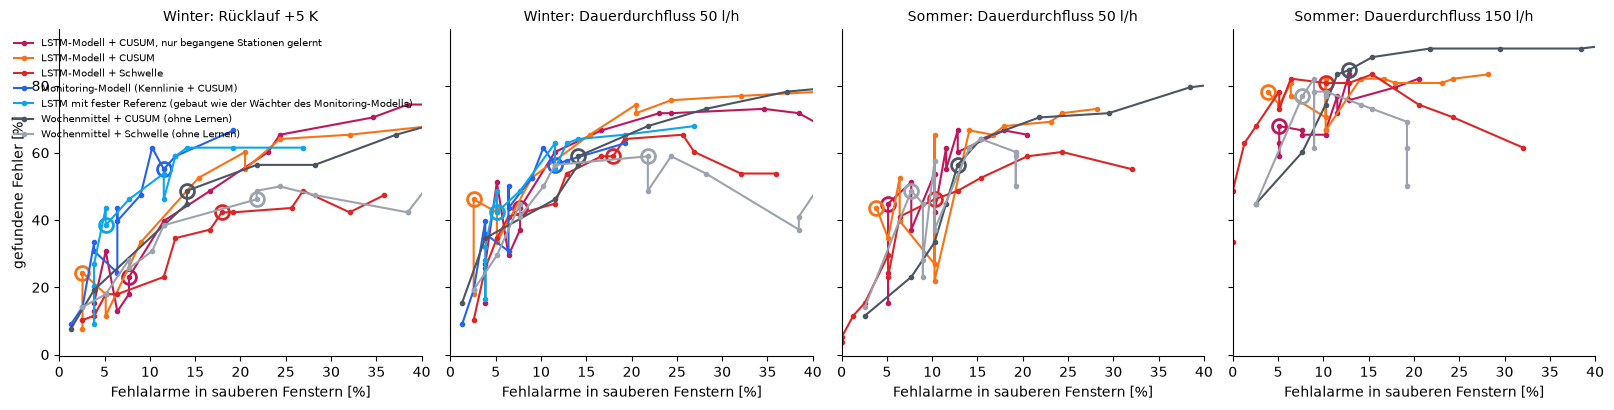

In [22]:
SK = fv.stoerungen_kurve(ST, w)
zeigen = [("Winter", "Rücklauf +5 K"), ("Winter", "Dauerdurchfluss 50 l/h"), ("Sommer", "Dauerdurchfluss 50 l/h"),
          ("Sommer", "Dauerdurchfluss 150 l/h")]
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2), sharey=True)
for ax, (saison, art) in zip(axes, zeigen):
    for key, g in SK[(SK["saison"] == saison) & (SK["art"] == art)].groupby("key"):
        g = g.sort_values("Fehlalarmquote")
        ax.plot(100 * g["Fehlalarmquote"], 100 * g["Trefferquote"], "-o", ms=3, color=farben[key], label=fv.WAECHTER[key])
        s = g[g["gewählt"]]
        ax.plot(100 * s["Fehlalarmquote"], 100 * s["Trefferquote"], "o", ms=10, mfc="none", mec=farben[key], mew=2)
    ax.set_title(f"{saison}: {art}", fontsize=10)
    ax.set_xlabel("Fehlalarme in sauberen Fenstern [%]")
    ax.set_xlim(0, 40)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("gefundene Fehler [%]")
axes[0].legend(frameon=False, fontsize=7)
fig.tight_layout()
fv.speichere(fig, "05_testB_kurven")
plt.show()

In [23]:
def bester_bei(g, fa):
    ok = g[g["Fehlalarmquote"] <= fa + 1e-9]
    return ok["Trefferquote"].max() if len(ok) else np.nan

gleich10 = SK.groupby(["saison", "art", "Wächter"]).apply(lambda g: bester_bei(g, 0.10)).unstack("Wächter")
gleich5 = SK.groupby(["saison", "art", "Wächter"]).apply(lambda g: bester_bei(g, 0.05)).unstack("Wächter")
print("Trefferquote bei höchstens 10 % Fehlalarmen")
display(gleich10.round(2))
print("Trefferquote bei höchstens 5 % Fehlalarmen")
gleich5.round(2)

Trefferquote bei höchstens 10 % Fehlalarmen


Wächter                              LSTM mit fester Referenz (gebaut wie der Wächter des Monitoring-Modells)  LSTM-Modell + CUSUM  LSTM-Modell + CUSUM, nur begangene Stationen gelernt  LSTM-Modell + Schwelle  \
saison art                                                                                                                                                                                                         
Sommer Dauerdurchfluss 150 l/h                                                     NaN                                        0.81                                               0.68                       0.82   
       Dauerdurchfluss 50 l/h                                                      NaN                                        0.53                                               0.51                       0.41   
       Fühler hängt                                                                NaN                                        0.36                                               0.33                       0.31   
       Regelhysterese 6 h                                                          NaN                                        0.10                                               0.09                       0.12   
       Rücklauf +5 K                                                               NaN                                        0.24                                               0.14                       0.22   
       schleichend +5 K in 30 Tagen                                                NaN                                        0.24                                               0.19                       0.22   
Winter Dauerdurchfluss 150 l/h                                                    0.74                                        0.73                                               0.72                       0.63   
       Dauerdurchfluss 50 l/h                                                     0.49                                        0.53                                               0.51                       0.41   
       Fühler hängt                                                               0.44                                        0.38                                               0.37                       0.19   
       Regelhysterese 6 h                                                         0.12                                        0.15                                               0.12                       0.06   
       Rücklauf +5 K                                                              0.46                                        0.33                                               0.31                       0.18   
       schleichend +5 K in 30 Tagen                                               0.38                                        0.27                                               0.28                       0.28   

Wächter                              Monitoring-Modell (Kennlinie + CUSUM)  Wochenmittel + CUSUM (ohne Lernen)  Wochenmittel + Schwelle (ohne Lernen)  
saison art                                                                                                                                             
Sommer Dauerdurchfluss 150 l/h                                         NaN                                0.60                                   0.82  
       Dauerdurchfluss 50 l/h                                          NaN                                0.23                                   0.49  
       Fühler hängt                                                    NaN                                0.12                                   0.31  
       Regelhysterese 6 h                                              NaN                                0.08                                   0.12  
       Rücklauf +5 K                                                   NaN                                0.15         

Trefferquote bei höchstens 5 % Fehlalarmen


Wächter                              LSTM mit fester Referenz (gebaut wie der Wächter des Monitoring-Modells)  LSTM-Modell + CUSUM  LSTM-Modell + CUSUM, nur begangene Stationen gelernt  LSTM-Modell + Schwelle  \
saison art                                                                                                                                                                                                         
Sommer Dauerdurchfluss 150 l/h                                                     NaN                                        0.78                                                NaN                       0.68   
       Dauerdurchfluss 50 l/h                                                      NaN                                        0.44                                                NaN                       0.15   
       Fühler hängt                                                                NaN                                        0.36                                                NaN                       0.17   
       Regelhysterese 6 h                                                          NaN                                        0.08                                                NaN                       0.04   
       Rücklauf +5 K                                                               NaN                                        0.12                                                NaN                       0.10   
       schleichend +5 K in 30 Tagen                                                NaN                                        0.18                                                NaN                       0.10   
Winter Dauerdurchfluss 150 l/h                                                    0.63                                        0.69                                               0.45                       0.53   
       Dauerdurchfluss 50 l/h                                                     0.32                                        0.46                                               0.27                       0.26   
       Fühler hängt                                                               0.29                                        0.27                                               0.13                       0.13   
       Regelhysterese 6 h                                                         0.04                                        0.10                                               0.04                       0.05   
       Rücklauf +5 K                                                              0.27                                        0.24                                               0.15                       0.12   
       schleichend +5 K in 30 Tagen                                               0.26                                        0.18                                               0.15                       0.16   

Wächter                              Monitoring-Modell (Kennlinie + CUSUM)  Wochenmittel + CUSUM (ohne Lernen)  Wochenmittel + Schwelle (ohne Lernen)  
saison art                                                                                                                                             
Sommer Dauerdurchfluss 150 l/h                                         NaN                                0.45                                   0.45  
       Dauerdurchfluss 50 l/h                                          NaN                                0.12                                   0.14  
       Fühler hängt                                                    NaN                                0.03                                   0.05  
       Regelhysterese 6 h                                              NaN                                0.03                                   0.03  
       Rücklauf +5 K                                                   NaN                                0.05         

### 8.1 Was Test B heißt

- Winter: Das Monitoring-Modell findet bei gleicher Fehlalarmquote am meisten. Trefferquote bei höchstens 10 % Fehlalarmen:

  | eingebauter Fehler | Monitoring-Modell | LSTM feste Referenz | Prognose-LSTM |
  |---|---:|---:|---:|
  | Rücklauf +5 K | 47 % | 46 % | 33 % |
  | schleichend +5 K | 42 % | 38 % | 27 % |
  | Fühler hängt | 46 % | 44 % | 38 % |
  | Dauerdurchfluss 150 l/h | 77 % | 74 % | 73 % |
  | Dauerdurchfluss 50 l/h | 53 % | 49 % | 53 % |

- Sommer: Nur das Prognose-LSTM kann prüfen. Mit CUSUM bei höchstens 5 % Fehlalarmen: 78 % der Dauerdurchflüsse 150 l/h (Wochenmittel 45 %), 44 % bei 50 l/h (Wochenmittel 12 bis 14 %).
- Prognose-LSTM nur begangene ist im Sommer schwächer (150 l/h: 68 % statt 81 % bei 10 % Fehlalarmen, unter 5 % gar nicht). Für warme Tage bleibt die Fassung auf allen Stationen.
- Für das LSTM CUSUM statt Schwelle: gleiche oder bessere Treffer bei 3 bis 4 % statt 10 bis 18 % Fehlalarmen.
- Regelhysterese findet keins (höchstens 15 %), weil alle mit Tagesmitteln rechnen. Dauerdurchfluss wird nach 1 bis 3 Tagen gemeldet, schleichende Fehler nach 2 bis 3 Wochen.
- Grenze: Eingebaute Fehler sind sauber, echte nicht. Werte bei 5 % Fehlalarmen schwanken stärker.

## 9 Ist das Monitoring-Modell nur im Vorteil, weil es für den Winter gebaut ist?

- Drei Wächter auf denselben Heiztagen: die Kennlinie des Monitoring-Modells, LSTM mit derselben Bauweise (feste Referenz), Prognose-LSTM.
- Test A ohne gewählte Einstellung: Vorsprung vor der Kontrolle beim Punkt jeder Kurve, der 4,3 Alarmen je Station und Jahr (Arbeitslast des Monitoring-Modells) am nächsten liegt.
- Test B: Trefferquote im Winter bei höchstens 10 % Fehlalarmen. Dazu die Vorhersagegenauigkeit auf denselben Testtagen.

In [24]:
zeilen = []
for key in ["monitoring", "nv", "lstm_c"]:
    k = KA[KA["key"] == key].copy()
    nah = k.iloc[(k["Arbeitslast"] - 4.34).abs().argmin()]
    z = {"Wächter": fv.WAECHTER[key], "Test A: Arbeitslast": nah["Arbeitslast"], "Test A: Vorsprung [Pp.]": 100 * nah["Vorsprung"]}
    for art in ["Rücklauf +5 K", "schleichend +5 K in 30 Tagen", "Dauerdurchfluss 50 l/h", "Dauerdurchfluss 150 l/h", "Fühler hängt"]:
        z[f"Test B Winter: {art}"] = gleich10.loc[("Winter", art), fv.WAECHTER[key]]
    zeilen.append(z)
vergleich_nv = pd.DataFrame(zeilen).set_index("Wächter")
display(vergleich_nv.round(2).T)
m = w["verlauf"].merge(w["nv"]["verlauf"], on=["meter", "kanal", "datum"], suffixes=("_mm", "_nv"))
m = m[m["datum"] >= fv.TEST_START]
fehler = m.assign(Kennlinie=(m["wert_mm"] - m["erwartung_mm"]).abs(), LSTM_feste_Referenz=(m["wert_nv"] - m["erwartung_nv"]).abs())
print("Mittlerer absoluter Vorhersagefehler im Test (Median über Tage):")
fehler.groupby("kanal")[["Kennlinie", "LSTM_feste_Referenz"]].median().round(3)

Wächter,Monitoring-Modell (Kennlinie + CUSUM),LSTM mit fester Referenz (gebaut wie der Wächter des Monitoring-Modells),LSTM-Modell + CUSUM
Test A: Arbeitslast,4.34,4.06,4.58
Test A: Vorsprung [Pp.],18.15,16.81,-5.64
Test B Winter: Rücklauf +5 K,0.47,0.46,0.33
Test B Winter: schleichend +5 K in 30 Tagen,0.42,0.38,0.27
Test B Winter: Dauerdurchfluss 50 l/h,0.53,0.49,0.53
Test B Winter: Dauerdurchfluss 150 l/h,0.77,0.74,0.73
Test B Winter: Fühler hängt,0.46,0.44,0.38


Mittlerer absoluter Vorhersagefehler im Test (Median über Tage):


,Kennlinie,LSTM_feste_Referenz
kanal,,
kwh_pro_m3,3.621,3.310
log_volumen,0.250,0.236


- Gleich gut: Vorsprung vor der Kontrolle 18 Prozentpunkte (Monitoring-Modell) gegen 17 (LSTM feste Referenz) bei gut 4 Alarmen je Station und Jahr. Im Winter liegen die eingebauten Fehler 1 bis 4 Prozentpunkte auseinander.
- Das Netz sagt etwas genauer voraus (3,31 gegen 3,62 kWh/m³ bei der Abkühlung), daraus folgen aber keine besseren Alarme. Das Prognose-LSTM liegt bei gleicher Last unter der Kontrolle (−6 Prozentpunkte).
- Der Vorteil des Monitoring-Modells kommt von der festen Referenz, die bleibende Veränderungen nicht „vergisst“, nicht von der Gerade. Bei Gleichstand gewinnt das Einfachere: erklärbar, ohne Grafikkarte, je Station nachvollziehbar.
- Die Einstellzeit (31 Alarme) ist klein, die Wahl h = 15 für das Netz deshalb unsicher. Es zählen die Kurven.

## 10 Lohnt ein eigenes LSTM nur für den Sommer?

- Ein Prognose-LSTM lernt nur auf warmen Tagen (Tagesmittel ab 15 °C) und wird auf warmen Tagen der Probezeit kalibriert.
- Es läuft auf denselben Sommerfällen aus Test B wie das ganzjährige LSTM, Regel CUSUM, über alle Einstellungen.

In [25]:
som = fv.sommer_lstm_pruefen(w, e, ST, log=lambda *a: None)
k = som["lernkurve"]
print(f"Sommer-LSTM: {som['lern_ziele']} Lerntage, {som['pruef_ziele']} Prüftage; bester Prüffehler {k['validierung'].min():.2f} "
      f"(ganzjähriges LSTM: {w['lstm']['lernkurve']['validierung'].min():.2f})")
for grenze in (0.10, 0.05):
    print(f"Trefferquote bei höchstens {grenze:.0%} Fehlalarmen, Sommer")
    display(som["kurve"][som["kurve"]["Fehlalarmquote"] <= grenze + 1e-9].groupby(["art", "modell"])["Trefferquote"].max()
            .unstack().round(2))

Sommer-LSTM: 5729 Lerntage, 2038 Prüftage; bester Prüffehler 12.73 (ganzjähriges LSTM: 0.10)
Trefferquote bei höchstens 10% Fehlalarmen, Sommer


modell,ganzjährig gelernt,nur Sommertage gelernt
art,,
Dauerdurchfluss 150 l/h,0.81,0.83
Dauerdurchfluss 50 l/h,0.53,0.49
Fühler hängt,0.36,0.38
Regelhysterese 6 h,0.10,0.14
Rücklauf +5 K,0.24,0.18
schleichend +5 K in 30 Tagen,0.24,0.23


Trefferquote bei höchstens 5% Fehlalarmen, Sommer


modell,ganzjährig gelernt
art,
Dauerdurchfluss 150 l/h,0.78
Dauerdurchfluss 50 l/h,0.44
Fühler hängt,0.36
Regelhysterese 6 h,0.08
Rücklauf +5 K,0.12
schleichend +5 K in 30 Tagen,0.18


- Ein eigenes Sommer-LSTM lohnt sich nicht. Es hat nur den Sommer 2023 zum Lernen und liegt schon im Frühjahr 2024 weit daneben (Prüffehler 12,7 gegen 0,10).
- Bei 10 % Fehlalarmen mal besser, mal schlechter (150 l/h: 83 % gegen 81 %; Rücklauf +5 K: 18 % gegen 24 %). Unter 5 % Fehlalarme kommt es nicht.
- Die Aufteilung nach Jahreszeit gelingt besser über die Wahl des Wächters: Heizperiode Monitoring-Modell, warme Tage ganzjähriges Prognose-LSTM.

## 11 Test C: Welche Station hat welchen Fehler?

- Frage: Kann ein Modell aus Daten vor der Begehung sagen, welche Maßnahme nötig war?
- 53 begangene Stationen mit genug Daten im Winter 23/24 und Sommer 2024 (wie in Notebook 31, 38 und im Audit). Fünf Durchgänge mit je etwa 11 Teststationen. Das LSTM-Embedding wird je Durchgang nur auf begangenen Lernstationen neu gelernt.
- Kandidaten: logistische Regression (LR) auf Kennzahlen, Kennzahlen + LSTM, LSTM allein; XGBoost auf Kennzahlen und Kennzahlen + LSTM; Regeln ohne Lernen; Netz-Score und Fehlerbild des Monitoring-Modells (einmal für Winter 23/24, ohne Labels).
- Gemessen: AUC (wie oft steht eine Station mit Befund vor einer ohne; 0,5 = Raten, 1 = perfekt) und Konfusionsmatrix an der festen Grenze.

In [26]:
KL = fv.klassifikation(e, log=lambda *a: None, nur_begangene=True)
print("Stationen:", len(KL["basis"]), "| Ventil:", int(KL["basis"]["ventil"].sum()), "| Dämmung:", int(KL["basis"]["daemmung"].sum()))
KL["fold_info"]

Stationen: 53 | Ventil: 11 | Dämmung: 22


,fold,Teststationen,Lernstationen Encoder,Lernpaare,Prüfpaare,Ventil im Test
0,0,11,43,16988,2227,2
1,1,11,43,16282,2167,2
2,2,11,43,17250,2116,3
3,3,10,44,17339,2171,2
4,4,10,44,18009,2235,2


In [27]:
assert len(KL["basis"]) == 53
for k, (tr, te) in enumerate(KL["folds"]):
    assert not set(e["gruppen"].reindex(KL["basis"].index[tr])) & set(e["gruppen"].reindex(KL["basis"].index[te]))
netz = fv.netzvergleich(e["serien"], termine, e["anschluss"], e["bhkw"])
mm = fv.monitoring_je_station(netz, "23/24", al_g)
print("Netzvergleich Winter 23/24:", len(mm), "Stationen,", int(mm["auffaellig"].sum()), "auffällig")
print("Fehlerbilder:", mm["fehlerbild"].replace("", "keins").value_counts().to_dict())

Netzvergleich Winter 23/24: 86 Stationen, 9 auffällig
Fehlerbilder: {'keins': 62, 'unruhig': 9, 'ventil': 8, 'durchfluss_je_kw': 3, 'rücklauf': 2, 'regelung': 1, 'durchfluss': 1}


### 11.1 Ventil (Reparatur nach Folie 5)

In [28]:
tab_ventil = fv.bewertung_tabelle(KL, mm, e["gruppen"], "ventil")
tab_ventil.round(3)

,Kandidat,Stationen,Befunde,AUC,AUC unten,AUC oben,Differenz zu Regel Sommernacht-Anteil,Diff. unten,Diff. oben,gefunden,übersehen,Fehlalarm,richtig ruhig,Precision,Recall,F1
0,LR Kennzahlen,53,11,0.816,0.598,0.976,-0.035,-0.113,0.034,8,3,5,37,0.615,0.727,0.667
1,LR Kennzahlen + LSTM,53,11,0.883,0.731,0.996,0.032,-0.092,0.167,8,3,3,39,0.727,0.727,0.727
2,LR nur LSTM-Embedding,53,11,0.833,0.641,0.975,-0.017,-0.202,0.128,8,3,4,38,0.667,0.727,0.696
3,Regel Sommernacht-Anteil,53,11,0.851,0.679,0.980,NaN,NaN,NaN,9,2,5,37,0.643,0.818,0.720
4,XGBoost Kennzahlen,53,11,0.816,0.604,0.978,-0.035,-0.114,0.015,7,4,4,38,0.636,0.636,0.636
5,XGBoost Kennzahlen + LSTM,53,11,0.877,0.752,0.972,0.026,-0.054,0.136,7,4,4,38,0.636,0.636,0.636
6,Monitoring-Modell (Netz-Score / Fehlerbild),53,11,0.734,0.548,0.906,-0.117,-0.286,0.028,4,7,0,42,1.000,0.364,0.533


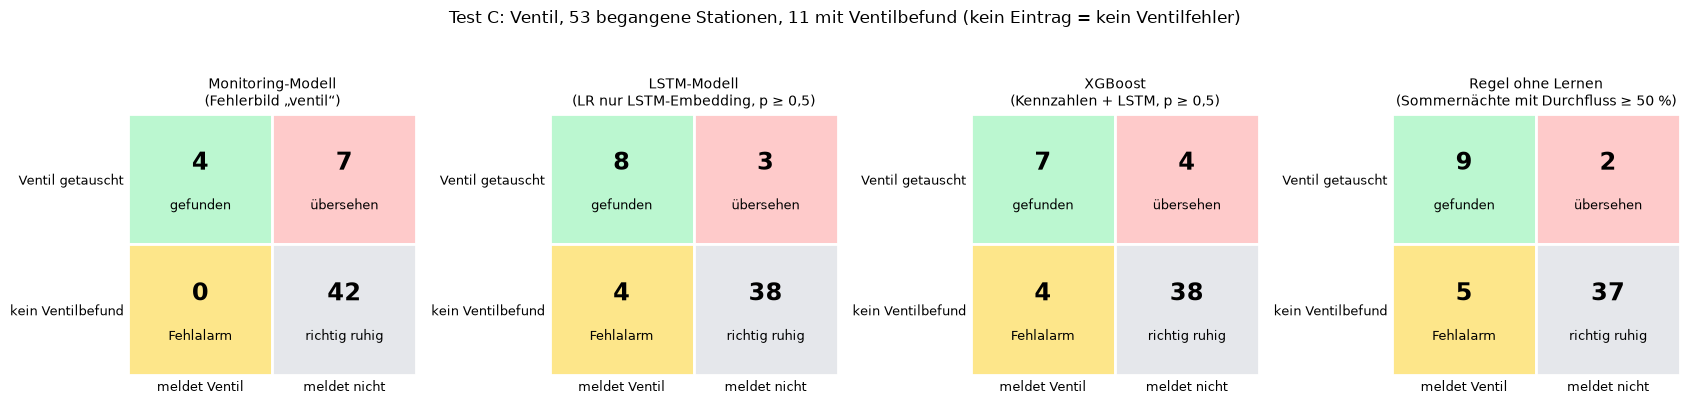

In [29]:
bv = fv.oof_breit(KL, "ventil").join(mm[["fehlerbild"]])
kandidaten_bild = [("Monitoring-Modell\n(Fehlerbild „ventil“)", bv["fehlerbild"].eq("ventil")),
                   (f"LSTM-Modell\n({fv.ENDMODELL}, p ≥ 0,5)", bv[fv.ENDMODELL] >= 0.5),
                   ("XGBoost\n(Kennzahlen + LSTM, p ≥ 0,5)", bv["XGBoost Kennzahlen + LSTM"] >= 0.5),
                   ("Regel ohne Lernen\n(Sommernächte mit Durchfluss ≥ 50 %)", bv["Regel Sommernacht-Anteil"] >= 0.5)]
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, (name, entscheidung) in zip(axes, kandidaten_bild):
    fv.zeichne_vierfeld(ax, fv.vierfeld(bv["y"], entscheidung), name, spalte_ja="meldet Ventil", spalte_nein="meldet nicht",
                        zeile_ja="Ventil getauscht", zeile_nein="kein Ventilbefund")
fig.suptitle("Test C: Ventil, 53 begangene Stationen, 11 mit Ventilbefund (kein Eintrag = kein Ventilfehler)", y=1.05)
fig.tight_layout()
fv.speichere(fig, "06_testC_ventil")
plt.show()

### 11.2 Dämmung

In [30]:
tab_daemmung = fv.bewertung_tabelle(KL, mm, e["gruppen"], "daemmung")
tab_daemmung.round(3)

,Kandidat,Stationen,Befunde,AUC,AUC unten,AUC oben,Differenz zu LR Kennzahlen,Diff. unten,Diff. oben,gefunden,übersehen,Fehlalarm,richtig ruhig,Precision,Recall,F1
0,LR Kennzahlen,53,22,0.735,0.589,0.864,NaN,NaN,NaN,14.0,8.0,7.0,24.0,0.667,0.636,0.651
1,LR Kennzahlen + LSTM,53,22,0.802,0.664,0.919,0.067,-0.045,0.183,14.0,8.0,5.0,26.0,0.737,0.636,0.683
2,LR nur LSTM-Embedding,53,22,0.789,0.648,0.905,0.054,-0.062,0.179,15.0,7.0,7.0,24.0,0.682,0.682,0.682
3,XGBoost Kennzahlen,53,22,0.686,0.524,0.834,-0.048,-0.180,0.073,14.0,8.0,10.0,21.0,0.583,0.636,0.609
4,XGBoost Kennzahlen + LSTM,53,22,0.865,0.744,0.956,0.130,0.006,0.264,15.0,7.0,4.0,27.0,0.789,0.682,0.732
5,Monitoring-Modell (Netz-Score / Fehlerbild),53,22,0.380,0.214,0.552,-0.355,-0.587,-0.108,NaN,NaN,NaN,NaN,NaN,NaN,NaN


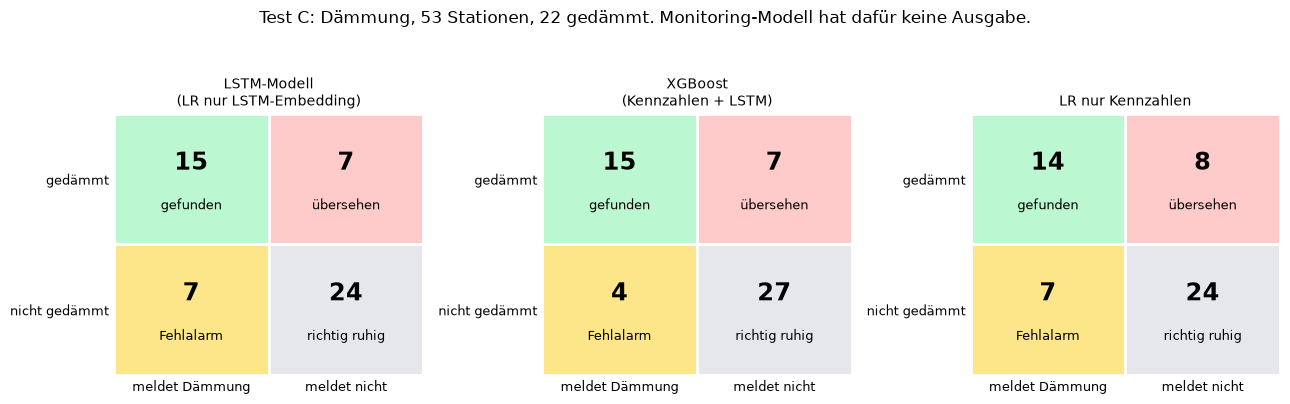

In [31]:
bd = fv.oof_breit(KL, "daemmung")
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (name, spalte) in zip(axes, [(f"LSTM-Modell\n({fv.ENDMODELL})", fv.ENDMODELL),
                                     ("XGBoost\n(Kennzahlen + LSTM)", "XGBoost Kennzahlen + LSTM"),
                                     ("LR nur Kennzahlen", "LR Kennzahlen")]):
    fv.zeichne_vierfeld(ax, fv.vierfeld(bd["y"], bd[spalte] >= 0.5), name, spalte_ja="meldet Dämmung",
                        spalte_nein="meldet nicht", zeile_ja="gedämmt", zeile_nein="nicht gedämmt")
fig.suptitle("Test C: Dämmung, 53 Stationen, 22 gedämmt. Monitoring-Modell hat dafür keine Ausgabe.", y=1.05)
fig.tight_layout()
fv.speichere(fig, "07_testC_daemmung")
plt.show()

### 11.3 Überdimensionierung (Kapazitätsanpassung) und übrige Maßnahmen

In [32]:
tab_ueber = fv.bewertung_tabelle(KL, mm, e["gruppen"], "ueberdimensioniert")
tab_ueber.round(3)

,Kandidat,Stationen,Befunde,AUC,AUC unten,AUC oben,Differenz zu LR Kennzahlen,Diff. unten,Diff. oben,gefunden,übersehen,Fehlalarm,richtig ruhig,Precision,Recall,F1
0,LR Kennzahlen,35,9,0.393,0.184,0.629,NaN,NaN,NaN,2.0,7.0,10.0,16.0,0.167,0.222,0.190
1,LR Kennzahlen + LSTM,35,9,0.325,0.121,0.546,-0.068,-0.260,0.107,2.0,7.0,11.0,15.0,0.154,0.222,0.182
2,LR nur LSTM-Embedding,35,9,0.491,0.264,0.724,0.098,-0.123,0.343,2.0,7.0,9.0,17.0,0.182,0.222,0.200
3,Regel Auslastung zum Vertrag,35,9,0.759,0.583,0.925,0.365,0.042,0.650,5.0,4.0,1.0,25.0,0.833,0.556,0.667
4,XGBoost Kennzahlen,35,9,0.530,0.328,0.727,0.137,-0.115,0.384,1.0,8.0,7.0,19.0,0.125,0.111,0.118
5,XGBoost Kennzahlen + LSTM,35,9,0.462,0.273,0.652,0.068,-0.200,0.308,0.0,9.0,7.0,19.0,0.000,0.000,0.000
6,Monitoring-Modell (Netz-Score / Fehlerbild),35,9,0.598,0.352,0.837,0.205,-0.107,0.500,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [33]:
rest = []
for ziel in ["durchfluss", "temperatur", "filter"]:
    t = fv.bewertung_tabelle(KL, mm, e["gruppen"], ziel)
    for _, z in t.iterrows():
        rest.append({"Maßnahme": fv.ZIEL_TEXT[ziel], "Kandidat": z["Kandidat"], "Befunde": z["Befunde"],
                     "AUC": z["AUC"], "AUC unten": z["AUC unten"], "AUC oben": z["AUC oben"]})
rest = pd.DataFrame(rest)
rest.pivot_table(index="Kandidat", columns="Maßnahme", values="AUC").round(2)

Maßnahme,Durchfluss neu eingestellt,Filter gereinigt,Rücklauf-Sollwert gesenkt
Kandidat,,,
LR Kennzahlen,0.32,0.43,0.38
LR Kennzahlen + LSTM,0.29,0.30,0.33
LR nur LSTM-Embedding,0.36,0.31,0.30
Monitoring-Modell (Netz-Score / Fehlerbild),0.53,0.57,0.51
XGBoost Kennzahlen,0.37,0.48,0.38
XGBoost Kennzahlen + LSTM,0.42,0.46,0.26


- Werte deutlich unter 0,5 sind kein umgekehrtes Signal. Bei kleinen Stichproben landen Modelle ohne Zusammenhang oft darunter. Schließt das Intervall 0,5 ein oder liegt darunter: nicht erkennbar.

### 11.4 Stabilität bei anderen Startgewichten

- Das Embedding hängt von den zufälligen Startgewichten ab. Dieselben Folds mit zwei weiteren Seeds.

In [34]:
stab = fv.stabilitaet(e, seeds=(1, 2), log=lambda *a: None)
haupt = []
for ziel in ("ventil", "daemmung"):
    b = fv.oof_breit(KL, ziel)
    for c in ("LR Kennzahlen + LSTM", "LR nur LSTM-Embedding", "XGBoost Kennzahlen + LSTM"):
        from sklearn.metrics import roc_auc_score
        vf = fv.vierfeld(b["y"], b[c] >= 0.5)
        haupt.append({"Seed": 0, "Ziel": ziel, "Kandidat": c, "AUC": roc_auc_score(b["y"], b[c]),
                      "gefunden": vf["gefunden"], "Fehlalarm": vf["Fehlalarm"]})
stab = pd.concat([pd.DataFrame(haupt), stab], ignore_index=True)
stab.pivot_table(index=["Ziel", "Kandidat"], columns="Seed", values="AUC").round(3)

Seed                                    0      1      2
Ziel     Kandidat                                      
daemmung LR Kennzahlen + LSTM       0.802  0.796  0.836
         LR nur LSTM-Embedding      0.789  0.789  0.768
         XGBoost Kennzahlen + LSTM  0.865  0.765  0.743
ventil   LR Kennzahlen + LSTM       0.883  0.890  0.885
         LR nur LSTM-Embedding      0.833  0.840  0.903
         XGBoost Kennzahlen + LSTM  0.877  0.842  0.877

### 11.5 Gegenprobe: Encoder auf allen Stationen statt nur auf begangenen

In [35]:
from sklearn.metrics import roc_auc_score
namen = ("LR Kennzahlen + LSTM", "LR nur LSTM-Embedding", "XGBoost Kennzahlen + LSTM")
KL_alle = fv.klassifikation(e, log=lambda *a: None, ziele=("ventil", "daemmung"), kandidaten=namen, nur_begangene=False)
zeilen = []
for fassung, kl in (("nur begangene (Hauptlauf)", KL), ("alle Stationen (Gegenprobe)", KL_alle)):
    for ziel in ("ventil", "daemmung"):
        b = fv.oof_breit(kl, ziel)
        for c in namen:
            vf = fv.vierfeld(b["y"], b[c] >= 0.5)
            zeilen.append({"Encoder gelernt auf": fassung, "Ziel": ziel, "Kandidat": c, "AUC": roc_auc_score(b["y"], b[c]),
                           "gefunden": vf["gefunden"], "Fehlalarm": vf["Fehlalarm"]})
vergleich_beg = pd.DataFrame(zeilen)
vergleich_beg.pivot_table(index=["Ziel", "Kandidat"], columns="Encoder gelernt auf", values=["AUC", "Fehlalarm"]).round(3)

AUC                                             Fehlalarm                          
Encoder gelernt auf                alle Stationen (Gegenprobe) nur begangene (Hauptlauf) alle Stationen (Gegenprobe) nur begangene (Hauptlauf)
Ziel     Kandidat                                                                                                                             
daemmung LR Kennzahlen + LSTM                            0.782                     0.802                         7.0                       5.0
         LR nur LSTM-Embedding                           0.812                     0.789                         7.0                       7.0
         XGBoost Kennzahlen + LSTM                       0.716                     0.865                         6.0                       4.0
ventil   LR Kennzahlen + LSTM                            0.881                     0.883                         5.0                       3.0
         LR nur LSTM-Embedding                           0.866                     0.833                         6.0                       4.0
         XGBoost Kennzahlen + LSTM                       0.805                     0.877                         3.0                       4.0

### 11.6 XGBoost erklärt: welche Merkmale den Ventilverdacht tragen

- XGBoost zerlegt jede Entscheidung in Beiträge je Merkmal (TreeSHAP). Positive Beiträge heben den Verdacht.
- Ausgangswert plus alle Beiträge ergibt den Logit, daraus p = 1 / (1 + e^(−Logit)).

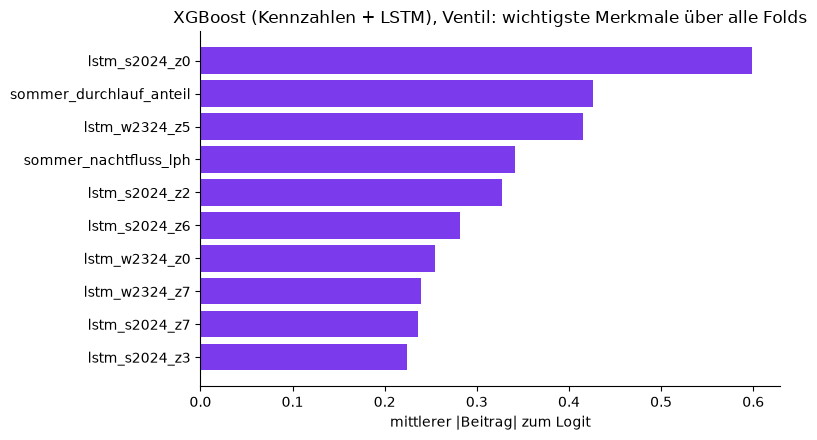

Die 5 wichtigsten Merkmale je Fold:
  Fold 0: lstm_s2024_z0, lstm_w2324_z4, lstm_w2324_z2, lstm_w2324_z7, lstm_w2324_z5
  Fold 1: lstm_s2024_z2, lstm_w2324_z7, sommer_durchlauf_anteil, streubreite_betriebspunkte, lstm_s2024_z6
  Fold 2: sommer_nachtfluss_lph, lstm_s2024_z6, lstm_w2324_z5, lstm_s2024_z0, lstm_w2324_z2
  Fold 3: sommer_durchlauf_anteil, lstm_s2024_z7, lstm_s2024_z3, lstm_w2324_z0, lstm_s2024_z2
  Fold 4: lstm_w2324_z5, lstm_w2324_z0, lstm_s2024_z0, lstm_s2024_z5, lstm_s2024_z4


In [36]:
beitr = KL["beitraege"].drop(columns=["fold"])
wichtig = beitr.drop(columns="basis").abs().mean().sort_values(ascending=False)
je_fold = KL["beitraege"].groupby("fold").apply(lambda g: g.drop(columns=["fold", "basis"], errors="ignore").abs().mean().nlargest(5).index.tolist())
fig, ax = plt.subplots(figsize=(8, 4.5))
top = wichtig.head(10)[::-1]
ax.barh(top.index, top.values, color=fv.FARBE_XGB)
ax.set_xlabel("mittlerer |Beitrag| zum Logit")
ax.set_title("XGBoost (Kennzahlen + LSTM), Ventil: wichtigste Merkmale über alle Folds")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fv.speichere(fig, "08_xgboost_beitraege")
plt.show()
print("Die 5 wichtigsten Merkmale je Fold:")
for k, liste in je_fold.items():
    print(f"  Fold {k}: {', '.join(liste)}")

In [37]:
fall = 68956351 if 68956351 in beitr.index else beitr.index[0]
b = beitr.loc[fall]
logit = b.sum()
zerlegung = b.drop("basis").sort_values(key=np.abs, ascending=False).head(6)
print(f"Station {fall}: Ausgangswert {b['basis']:+.2f}")
for name, wert in zerlegung.items():
    print(f"   {name:32s} {wert:+.2f}")
print(f"   übrige Merkmale                  {b.drop(['basis', *zerlegung.index]).sum():+.2f}")
print(f"Summe (Logit) {logit:+.2f}  ->  p(Ventil) = {1 / (1 + np.exp(-logit)):.2f}")
print("Kennzahlen dieser Station:", KL["kz"].loc[fall, ["sommer_durchlauf_anteil", "sommer_nachtfluss_lph", "winter_spreizung_last_k"]].round(2).to_dict())

Station 68956351: Ausgangswert +0.58
   sommer_nachtfluss_lph            +0.85
   lstm_s2024_z6                    -0.73
   lstm_w2324_z2                    +0.60
   lstm_s2024_z0                    -0.56
   lstm_w2324_z5                    +0.54
   winter_nacht_tag_fluss           -0.41
   übrige Merkmale                  +0.57
Summe (Logit) +1.43  ->  p(Ventil) = 0.81
Kennzahlen dieser Station: {'sommer_durchlauf_anteil': 1.0, 'sommer_nachtfluss_lph': 518.0, 'winter_spreizung_last_k': 5.91}


### 11.7 Die drei Klassen nach Folie 5

- Befund: Reparatur (Ventil getauscht), Regelungsoptimierung (Durchfluss eingestellt oder Sollwert gesenkt), keine dieser Maßnahmen.
- LSTM-Modell: p(Ventil) ≥ 0,5, sonst K-Means. Monitoring-Modell: Fehlerbild „ventil“, sonst anderes Fehlerbild, sonst keins.

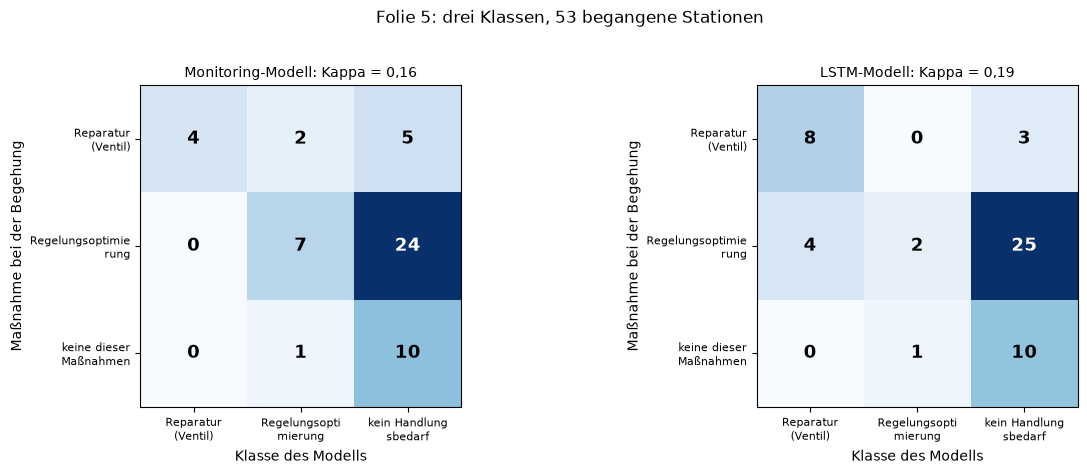

In [38]:
f5_befund = fv.folie5_befund(e["labels"].loc[KL["basis"].index])
p_v = fv.oof_breit(KL, "ventil")[fv.ENDMODELL]
f5_lstm = fv.folie5_lstm(p_v, KL["kmeans_klasse"].reindex(p_v.index))
f5_mm = fv.folie5_monitoring(mm["fehlerbild"].reindex(p_v.index).fillna(""))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, (name, vorhersage) in zip(axes, [("Monitoring-Modell", f5_mm), ("LSTM-Modell", f5_lstm)]):
    m = pd.crosstab(f5_befund, vorhersage).reindex(index=fv.F5_KLASSEN, columns=fv.F5_KLASSEN, fill_value=0)
    m.index = ["Reparatur (Ventil)", "Regelungsoptimierung", "keine dieser Maßnahmen"]
    k = fv.kappa(f5_befund, vorhersage)
    fv.zeichne_matrix(ax, m, f"{name}: Kappa = {k:.2f}".replace(".", ","), "Klasse des Modells", "Maßnahme bei der Begehung")
fig.suptitle("Folie 5: drei Klassen, 53 begangene Stationen", y=1.02)
fig.tight_layout()
fv.speichere(fig, "09_folie5_matrizen")
plt.show()

### 11.8 Gegenprobe mit späteren Daten: sinkt der Ventilverdacht nach dem Tausch?

- Beide Modelle laufen unverändert auf Winter 24/25 (und Sommer 2025, soweit vorhanden), also nach den Begehungen.
- Wo das Ventil getauscht wurde, sollte der Verdacht sinken. Prüfung an bekannten Stationen in späterer Zeit, ohne neu zu lernen.

In [39]:
teile = fv.fehlerklassen_teile(KL)
gp = fv.gegenprobe_nach_reparatur(teile, e, KL, netz)
from scipy import stats
zeilen = []
for gruppe, g in gp.groupby("gruppe"):
    g2 = g.dropna(subset=["p_ventil_vor", "p_ventil_nach"])
    p = stats.wilcoxon(g2["p_ventil_vor"], g2["p_ventil_nach"]).pvalue if len(g2) >= 6 else np.nan
    zeilen.append({"Gruppe": gruppe, "Stationen": len(g2), "p(Ventil) vorher, Median": g2["p_ventil_vor"].median(),
                   "p(Ventil) nachher, Median": g2["p_ventil_nach"].median(), "p (Wilcoxon)": p,
                   "Monitoring „ventil“ vorher": int(g["fehlerbild_vor"].eq("ventil").sum()),
                   "Monitoring „ventil“ nachher": int(g["fehlerbild_nach"].eq("ventil").sum())})
pd.DataFrame(zeilen).round(3)

,Gruppe,Stationen,"p(Ventil) vorher, Median","p(Ventil) nachher, Median",p (Wilcoxon),Monitoring „ventil“ vorher,Monitoring „ventil“ nachher
0,Ventil getauscht,11,0.707,0.254,0.042,4,1
1,"begangen, kein Ventil",43,0.265,0.075,0.000,0,1
2,nie begangen,37,0.301,0.231,0.066,4,4


### 11.9 Was Test C heißt

- Gelernt wird nur auf begangenen Stationen. Die Fassung mit allen Stationen liegt beim Dashboard-Modell etwas höher (Ventil 0,87 statt 0,83), hat aber mehr Fehlalarme (6 statt 4).
- Ventil: alle Kandidaten deutlich besser als Raten.
  - Dashboard-Modell (Regression nur auf 16 LSTM-Zahlen, `fv.ENDMODELL`): AUC 0,83 [0,64; 0,98], andere Seeds 0,84 und 0,90. Es schwankt mehr als die Fassung mit Kennzahlen (0,88 bis 0,89).
  - Sommernacht-Regel 0,85 [0,68; 0,98]. Unterschied −0,02 [−0,20; +0,13], nicht gesichert.
  - An der festen Grenze: LSTM 8 gefunden, 3 übersehen, 4 Fehlalarme (Precision 67 %); Regel 9 / 2 / 5 (64 %).
- Das Fehlerbild „ventil“ des Monitoring-Modells ist genau, aber streng: 4 von 4 richtig, nur 4 von 11 gefunden, Netz-Score AUC 0,73. Gut als Bestätigung.
- Dämmung: Dashboard-Modell 0,79 [0,65; 0,90], andere Seeds 0,79 und 0,77; Kennzahlen allein 0,73 (Vorsprung +0,05 [−0,06; +0,18], nicht gesichert). Gegen die beste angepasste Regel (0,61) deutlich vorn, knapp nicht gesichert (Abschnitt 18). Der Netz-Score des Monitoring-Modells zeigt umgekehrt (0,38), eine physikalische Erklärung fehlt.
- Überdimensionierung: nur die Regel „Spitzenlast zum alten Vertrag“ trägt (0,76 [0,58; 0,93], 5 von 9 bei 1 Fehlalarm). Gelernte Modelle höchstens 0,53.
- Durchfluss, Sollwert, Filter: für alle nicht erkennbar (AUC 0,26 bis 0,57). Das Dashboard zeigt sie nicht als erkannte Fehlerart.
- XGBoost ist nicht verlässlich: Ventil 0,88 im Test, in der Validierung aber hinter der Regression (0,81 gegen 0,84, Abschnitt 19.2); Dämmung 0,87, mit anderen Seeds 0,77 und 0,74. Die wichtigsten Merkmale wechseln je Durchgang, stabil sind nur Nachtdurchfluss und Sommernacht-Anteil. Nicht ins Dashboard.
- Folie 5: Reparatur trifft das Monitoring-Modell 4 von 11, das LSTM-Modell 8 von 11. Regelungsoptimierung trifft keins (24 bzw. 25 von 31 landen in „kein Handlungsbedarf“), Kappa 0,16 und 0,19. Nicht ins Dashboard.
- Gegenprobe nach Reparatur: Wo das Ventil getauscht wurde, sinkt der Score im Median von 0,71 auf 0,25 (p = 0,04), das Fehlerbild „ventil“ des Monitoring-Modells von 4 auf 1.
  - Der Score sinkt aber auch an begangenen Stationen ohne Ventiltausch (0,27 auf 0,08, p < 0,001), an nie begangenen kaum (0,30 auf 0,23, p = 0,07). Er reagiert auf jede Veränderung nach einer Begehung. Die frühere Fassung mit Kennzahlen blieb dort ruhig (0,11 auf 0,08).
  - Dieses Fehlerbild reagiert gezielt auf die Reparatur.

## 12 Test D: Dauerhaft schlecht, Effizienz und Potenzial

- Übereinstimmung: Potenzial des Monitoring-Modells (Winter 23/24) gegen die K-Means-Gruppe des LSTM-Strangs (Optimum/schlechter).
- Wirkung: Abkühlung bei 5 °C (kWh je m³) im Winter 24/25 minus 23/24, begangene gegen nicht begangene Stationen. Mehr Abkühlung heißt effizienter.
- Potenzial: Zeigt es vor der Begehung an, wo sie am meisten brachte?

In [40]:
wp = fv.wirkung_und_potenzial(w, netz, KL, termine)
pot_hoch = wp["potenzial"].isin(["mittel", "hoch"])
km_schlecht = wp["kmeans"].eq("schlechter")
print("Kappa Potenzial (mittel/hoch) gegen K-Means „schlechter“:", round(fv.kappa(pot_hoch[wp["kmeans"].notna()], km_schlecht[wp["kmeans"].notna()]), 2))
print(pd.crosstab(wp["potenzial"].replace("", "ohne"), wp["kmeans"].fillna("ohne"), margins=True))

Kappa Potenzial (mittel/hoch) gegen K-Means „schlechter“: 0.39
kmeans     Optimum  schlechter  All
potenzial                          
gering          37           0   37
hoch             7          13   20
mittel          18           4   22
All             62          17   79


Abkühlung bei 5 °C, Winter 24/25 minus 23/24: begangen +0.26 kWh/m³ (n = 41), nicht begangen -0.56 (n = 38); Unterschied +0.82, p = 0.371
Begangene: Potenzial vorher gegen Verbesserung, Spearman rho = 0.16, p = 0.304
Begangene, Verbesserung nach K-Means-Gruppe (Median): {'Optimum': -0.29, 'schlechter': 1.6} | n: {'Optimum': 34, 'schlechter': 7}


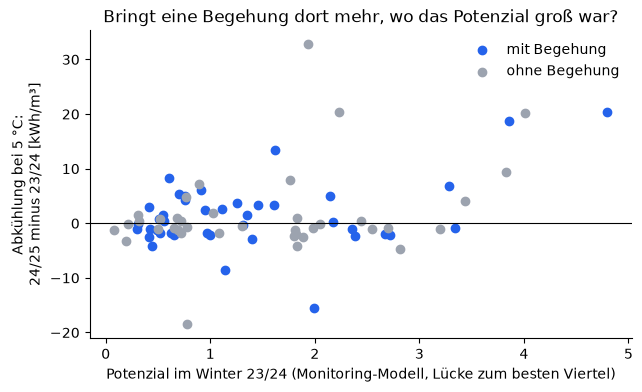

In [41]:
beg = wp[wp["begangen"]]
nicht = wp[~wp["begangen"]]
did = beg["delta_kwh_m3"].median() - nicht["delta_kwh_m3"].median()
p_mw = stats.mannwhitneyu(beg["delta_kwh_m3"], nicht["delta_kwh_m3"], alternative="greater").pvalue
rho, p_rho = stats.spearmanr(beg["potenzial_score"], beg["delta_kwh_m3"], nan_policy="omit")
print(f"Abkühlung bei 5 °C, Winter 24/25 minus 23/24: begangen {beg['delta_kwh_m3'].median():+.2f} kWh/m³ (n = {len(beg)}), "
      f"nicht begangen {nicht['delta_kwh_m3'].median():+.2f} (n = {len(nicht)}); Unterschied {did:+.2f}, p = {p_mw:.3f}")
print(f"Begangene: Potenzial vorher gegen Verbesserung, Spearman rho = {rho:.2f}, p = {p_rho:.3f}")
km = beg.dropna(subset=["kmeans"])
print("Begangene, Verbesserung nach K-Means-Gruppe (Median):", km.groupby("kmeans")["delta_kwh_m3"].median().round(2).to_dict(),
      "| n:", km["kmeans"].value_counts().to_dict())
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(beg["potenzial_score"], beg["delta_kwh_m3"], color=fv.FARBE_MONITORING, label="mit Begehung")
ax.scatter(nicht["potenzial_score"], nicht["delta_kwh_m3"], color="#9CA3AF", label="ohne Begehung")
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Potenzial im Winter 23/24 (Monitoring-Modell, Lücke zum besten Viertel)")
ax.set_ylabel("Abkühlung bei 5 °C:\n24/25 minus 23/24 [kWh/m³]")
ax.set_title("Bringt eine Begehung dort mehr, wo das Potenzial groß war?")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fv.speichere(fig, "10_potenzial_wirkung")
plt.show()

- Potenzial und K-Means passen mittelmäßig zusammen (Kappa 0,39). Alle 17 Stationen „schlechter“ haben mittleres oder hohes Potenzial, das Monitoring-Modell sieht aber 25 weitere.
- Dauerhaft schlechten Betrieb sieht nur der Netzvergleich. Beispiel Fall 1: drei Jahre offenes Ventil, vor der Reparatur Rang 1.
- Begangene Stationen kühlen im Winter 24/25 um 0,26 kWh/m³ besser, nicht begangene um 0,56 schlechter. Unterschied 0,82 kWh/m³, nicht gesichert (p = 0,37).
- Das Potenzial sagt kaum vorher, wo eine Begehung am meisten bringt (rho = 0,16, p = 0,30). K-Means „schlechter“ verbessert sich stärker (+1,6 gegen −0,3 kWh/m³), aber nur 7 Stationen.
- Fürs Dashboard: Netzeffizienz, Rang und Potenzial beschreiben die Lage im Netz. Keine Prognose der Einsparung, keine Euro- oder Prozentwerte.

## 13 Test E: Reihenfolge der Empfehlungen

- Wenn das Team nur 10 Stationen begehen kann: Wie viele davon hatten einen Ventilbefund?
- Die 53 begangenen Stationen werden sortiert nach der Priorität des Monitoring-Modells (dann Netz-Score), p(Ventil) des LSTM-Modells, XGBoost und Sommernacht-Regel. Zufall ergäbe etwa 2 (10 × 11/53).

In [42]:
rang = fv.oof_breit(KL, "ventil").join(mm[["prioritaet", "netz_score"]])
stufe = rang["prioritaet"].map({"hoch": 2, "mittel": 1, "niedrig": 0}).fillna(-1)
listen = {"Monitoring-Modell (Priorität, dann Netz-Score)": stufe * 100 + rang["netz_score"].fillna(-99),
          "LSTM-Modell (p Ventil)": rang[fv.ENDMODELL],
          "XGBoost (p Ventil)": rang["XGBoost Kennzahlen + LSTM"],
          "Regel Sommernacht-Anteil": rang["Regel Sommernacht-Anteil"]}
zeilen = []
for name, s in listen.items():
    top = s.sort_values(ascending=False).index[:10]
    zeilen.append({"Reihenfolge nach": name, "Ventilbefunde unter den ersten 10": int(rang.loc[top, "y"].sum())})
print("Priorität des Monitoring-Modells unter den 53:", rang["prioritaet"].value_counts().to_dict())
print("davon mit Ventilbefund:", rang.groupby("prioritaet")["y"].sum().to_dict())
pd.DataFrame(zeilen)

Priorität des Monitoring-Modells unter den 53: {'niedrig': 31, 'mittel': 21, 'hoch': 1}
davon mit Ventilbefund: {'hoch': 1, 'mittel': 6, 'niedrig': 4}


,Reihenfolge nach,Ventilbefunde unter den ersten 10
0,"Monitoring-Modell (Priorität, dann Netz-Score)",5
1,LSTM-Modell (p Ventil),7
2,XGBoost (p Ventil),7
3,Regel Sommernacht-Anteil,7


- Ventilbefunde unter den ersten 10: LSTM-Modell, XGBoost und Sommernacht-Regel je 7, Priorität des Monitoring-Modells 5, Zufall etwa 2.
- Die Stufe „hoch“ des Monitoring-Modells hatte vor den Begehungen nur 1 der 53 Stationen (mit Ventilbefund), „mittel“ 21 (davon 6 mit Ventil). Für eine Reihenfolge zu grob.
- Daraus folgt (umgesetzt in `dashboard_daten.empfehlungen`): Reparaturliste nach Ventil-Score des LSTM-Modells, das Fehlerbild „ventil“ des Monitoring-Modells hebt auf „hoch“.
- Die Stufen sind gesetzt, nicht gelernt. Ein echter Test wäre prospektiv: Stationen der Stufe „hoch“ und gleich viele zufällige blind begehen.

## 14 Neue Stationen, spätere Zeit, Jahreszeiten

| Frage | geprüft wo |
|---|---|
| bekannte HAST in späterer Zeit | Test A und B (ab Juni 2024), Gegenprobe Winter 24/25 (11.8) |
| neue HAST bei der Fehlerart | Test C: Teststationen nie im Encoder oder in der Regression |
| neue HAST beim Wächter | hier: LSTM ohne ein Fünftel der Stationen lernen |
| Jahreszeiten | Test B Sommer gegen Winter, Fehler je Monat |

In [43]:
neu = fv.lstm_neue_stationen(e, w, log=lambda *a: None)
t = neu["tage"]
print(len(neu["neu"]), "Stationen nie gesehen, gleiche Testtage für alle drei")
mae = t.groupby(["modell", "zaehler"])[["mae_rl", "mae_fluss"]].mean().groupby("modell").agg(["mean", "count"])
mae.round(2)

17 Stationen nie gesehen, gleiche Testtage für alle drei


mae_rl       mae_fluss      
                                  mean count      mean count
modell                                                      
Wochenmittel (ohne Lernen)        4.35    15     54.80    15
bekannt (Station war im Lernen)   3.49    15     46.33    15
neu (Station nie gesehen)         4.02    15     49.00    15

In [44]:
breit = t.groupby(["zaehler", "modell"])["mae_rl"].mean().unstack()
diff = (breit["neu (Station nie gesehen)"] - breit["bekannt (Station war im Lernen)"]).to_numpy()
rng = np.random.default_rng(0)
boot = [diff[rng.integers(0, len(diff), len(diff))].mean() for _ in range(2000)]
print(f"Rücklauf-Fehler neue minus bekannte Station: {diff.mean():+.2f} K, 95 % [{np.quantile(boot, .025):+.2f}; {np.quantile(boot, .975):+.2f}]")
diff_wm = (breit["neu (Station nie gesehen)"] - breit["Wochenmittel (ohne Lernen)"]).to_numpy()
boot = [diff_wm[rng.integers(0, len(diff_wm), len(diff_wm))].mean() for _ in range(2000)]
print(f"Rücklauf-Fehler neue Station minus Wochenmittel: {diff_wm.mean():+.2f} K, 95 % [{np.quantile(boot, .025):+.2f}; {np.quantile(boot, .975):+.2f}]")

Rücklauf-Fehler neue minus bekannte Station: +0.54 K, 95 % [+0.20; +1.07]
Rücklauf-Fehler neue Station minus Wochenmittel: -0.32 K, 95 % [-1.00; +0.40]


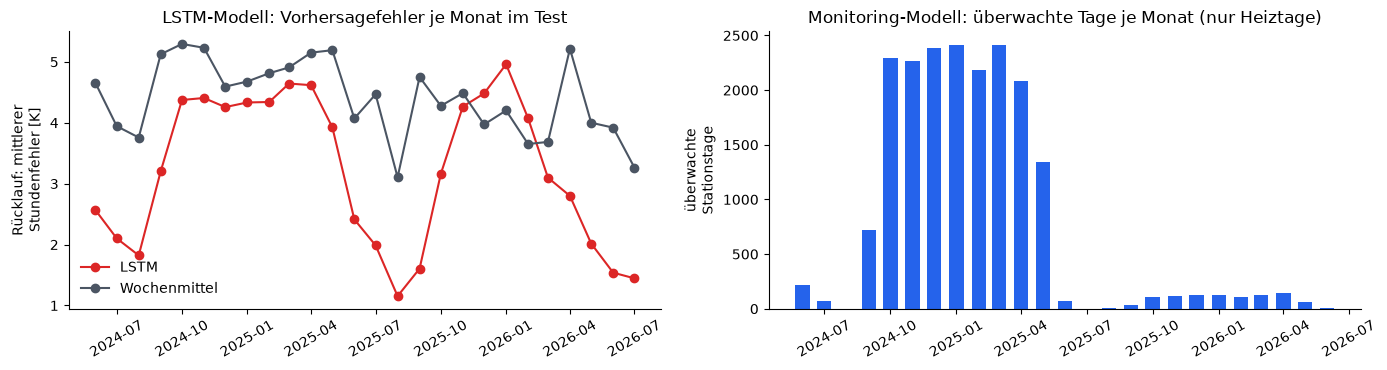

In [45]:
monat = w["abw"][w["abw"]["tag"] >= fv.TEST_START].assign(monat=lambda d: d["tag"].dt.to_period("M"))
monat_wm = w["abw_wm"][w["abw_wm"]["tag"] >= fv.TEST_START].assign(monat=lambda d: d["tag"].dt.to_period("M"))
v = w["verlauf"][(w["verlauf"]["datum"] >= fv.TEST_START) & (w["verlauf"]["kanal"] == "kwh_pro_m3")]
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
ax[0].plot(monat.groupby("monat")["mae_rl"].mean().to_timestamp(), "-o", color=fv.FARBE_LSTM, label="LSTM")
ax[0].plot(monat_wm.groupby("monat")["mae_rl"].mean().to_timestamp(), "-o", color="#4B5563", label="Wochenmittel")
ax[0].set_ylabel("Rücklauf: mittlerer\nStundenfehler [K]")
ax[0].set_title("LSTM-Modell: Vorhersagefehler je Monat im Test")
ax[0].legend(frameon=False)
mon = v.assign(monat=v["datum"].dt.to_period("M")).groupby("monat")
ax[1].bar(mon.size().index.to_timestamp(), mon.size().values, width=20, color=fv.FARBE_MONITORING)
ax[1].set_ylabel("überwachte\nStationstage")
ax[1].set_title("Monitoring-Modell: überwachte Tage je Monat (nur Heiztage)")
for a in ax:
    a.spines[["top", "right"]].set_visible(False)
    a.tick_params(axis="x", labelrotation=30)
fig.tight_layout()
fv.speichere(fig, "11_jahreszeiten")
plt.show()

In [46]:
bewertbar = fv.ab_wann_bewertbar(e, w)
print("Ab wann kann jedes Modell eine Station bewerten? (Tage nach dem ersten Messwert, Median über die Stationen)")
bewertbar[["Monitoring-Modell ab Tag", "LSTM-Wächter ab Tag"]].describe().loc[["count", "25%", "50%", "75%"]].round(0)

Ab wann kann jedes Modell eine Station bewerten? (Tage nach dem ersten Messwert, Median über die Stationen)


,Monitoring-Modell ab Tag,LSTM-Wächter ab Tag
count,93.0,93.0
25%,60.0,27.0
50%,60.0,29.0
75%,87.0,403.0


- Spätere Zeit: Beide Modelle funktionieren auf Daten nach dem Lernen. Neue Stationen bei der Fehlerart: Die AUC-Werte aus Test C gelten bereits für neue Stationen.
- Neue Stationen beim LSTM-Wächter (17 ohne sie gelernt): Rücklauf um 0,54 K [0,20; 1,07] schlechter vorhergesagt. Gegen das Wochenmittel nicht gesichert besser (−0,32 K [−1,00; +0,40]). Deshalb lernt der Wächter auf allen Stationen, die er überwachen soll.
- Ab wann bewertbar: Das Monitoring-Modell braucht 60 Heiztage mit 8 K Temperaturspanne (Median 60 Tage, sonst Warten auf die nächste Heizperiode), nutzt auch Tageswerte. Das LSTM braucht rund 4 Wochen volle Stundenwerte (Median 29 Tage), in jeder Jahreszeit.
- Jahreszeiten: Das LSTM sagt im Sommer genauer voraus (1 bis 2,5 K) als im Winter (4 bis 5 K), das Wochenmittel liegt ganzjährig bei 4 bis 5 K. Das Monitoring-Modell überwacht nur Oktober bis April. Die beiden ergänzen sich.
- 7 Stationen kann das Monitoring-Modell nicht einlernen (zu spät Daten), 6 davon auch das LSTM nicht. Das Dashboard zeigt „noch nicht bewertbar“, nicht „kein Alarm“.

## 15 Fallbeispiele mit echten Daten

- Je Fall vier Bilder: Abkühlung gegen Kennlinie des Monitoring-Modells, sein CUSUM-Konto mit h = 5, Rücklauf gegen LSTM-Erwartung, z-Werte des LSTM.
- Senkrechte Linien: Alarme (durchgezogen = schlechter, gepunktet = besser), grün = Begehungen.
- Die Fälle sind nach festen Regeln gewählt, nicht nach schönen Bildern.

{'ventil': True, 'daemmung': False, 'durchfluss': False, 'temperatur': True, 'filter': False, 'ueberdimensioniert': nan} | Begehung: ['09.09.2024']


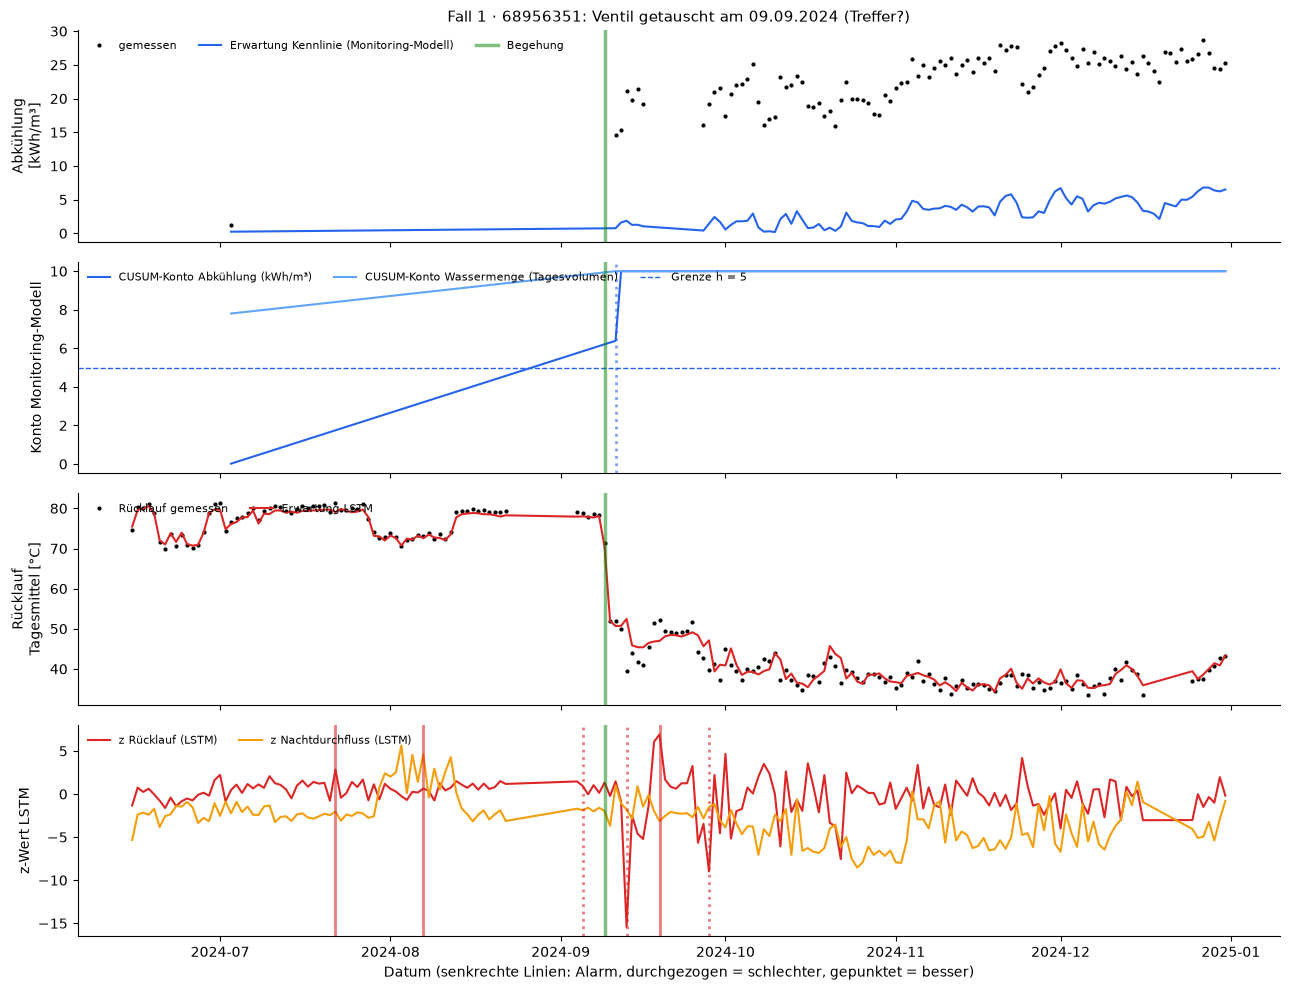

In [47]:
fall1 = 68956351
print(e["labels"].loc[fall1, fv.ZIELE].to_dict(), "| Begehung:", [f"{t:%d.%m.%Y}" for t in termine.get(fall1, [])])
fig = fv.fallbild(fall1, w, e, "2024-06-15", "2024-12-31", f"Fall 1 · {fall1}: Ventil getauscht am 09.09.2024 (Treffer?)")
fv.speichere(fig, "12_fall1")
plt.show()

Fall 2: Ventilbefund mit dem kleinsten Verdacht des LSTM-Modells (p = 0.10), Fehlerbild Monitoring-Modell: „durchfluss_je_kw“
Kennzahlen: {'sommer_durchlauf_anteil': 0.93, 'sommer_nachtfluss_lph': 46.0, 'winter_spreizung_last_k': 28.62, 'ruecklauf_lastgewichtet': 47.17}


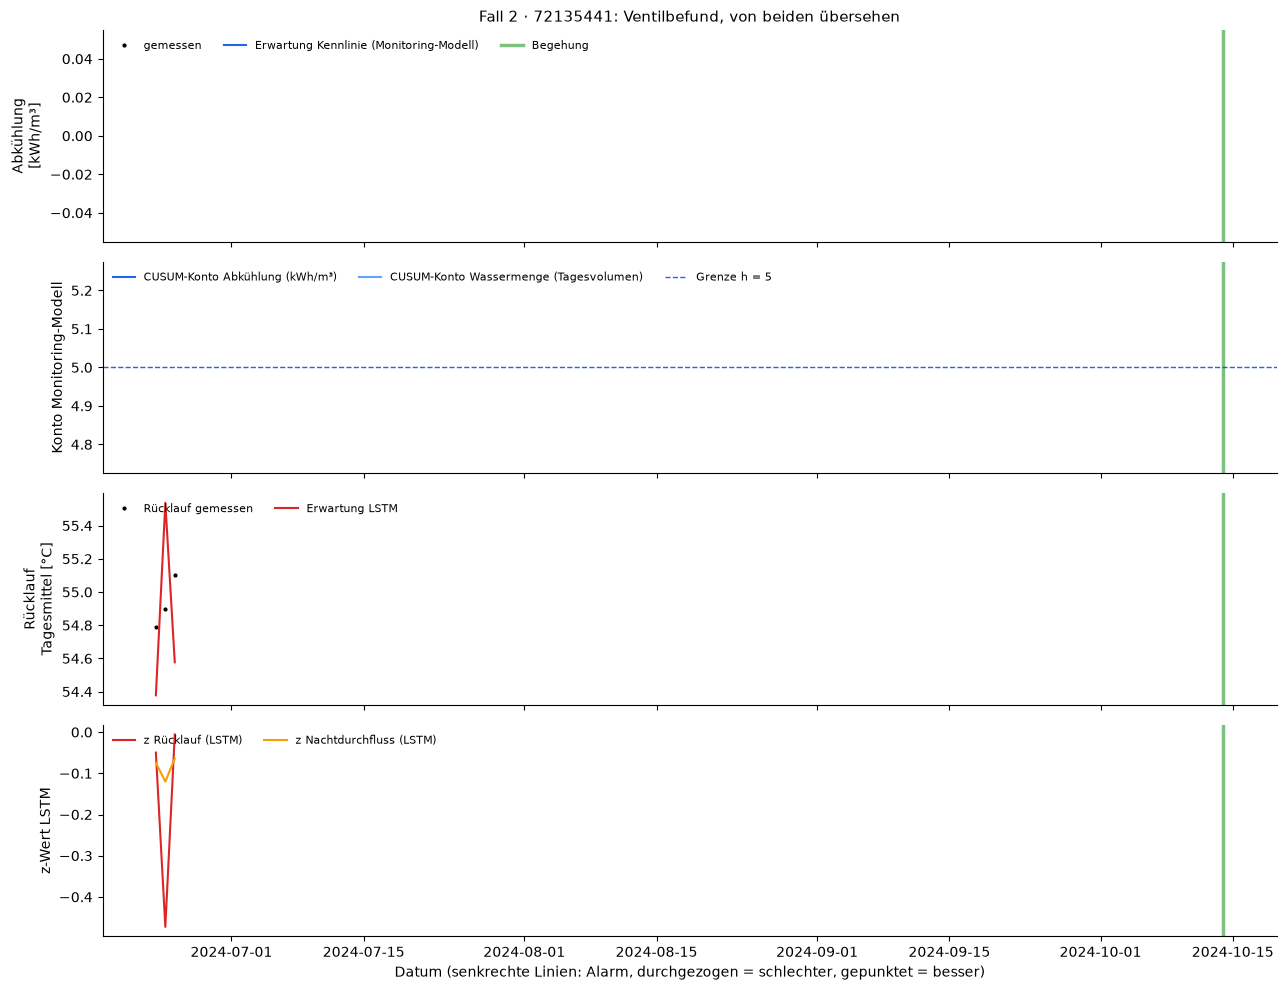

In [48]:
bv2 = fv.oof_breit(KL, "ventil").join(mm[["fehlerbild"]])
uebersehen = bv2[(bv2["y"] == 1) & ~bv2["fehlerbild"].eq("ventil")].sort_values(fv.ENDMODELL)
fall2 = int(uebersehen.index[0])
print(f"Fall 2: Ventilbefund mit dem kleinsten Verdacht des LSTM-Modells (p = {uebersehen.iloc[0][fv.ENDMODELL]:.2f}), "
      f"Fehlerbild Monitoring-Modell: „{uebersehen.iloc[0]['fehlerbild'] or 'keins'}“")
print("Kennzahlen:", KL["kz"].loc[fall2, ["sommer_durchlauf_anteil", "sommer_nachtfluss_lph", "winter_spreizung_last_k", "ruecklauf_lastgewichtet"]].round(2).to_dict())
d2 = min(termine.get(fall2, [pd.Timestamp("2024-10-01")]))
fig = fv.fallbild(fall2, w, e, d2 - pd.Timedelta(days=120), d2 + pd.Timedelta(days=90), f"Fall 2 · {fall2}: Ventilbefund, von beiden übersehen")
fv.speichere(fig, "12_fall2")
plt.show()

Fall 3: nie begangene Station mit den meisten Verschlechterungsalarmen beim Monitoring-Modell im Test: 72135453


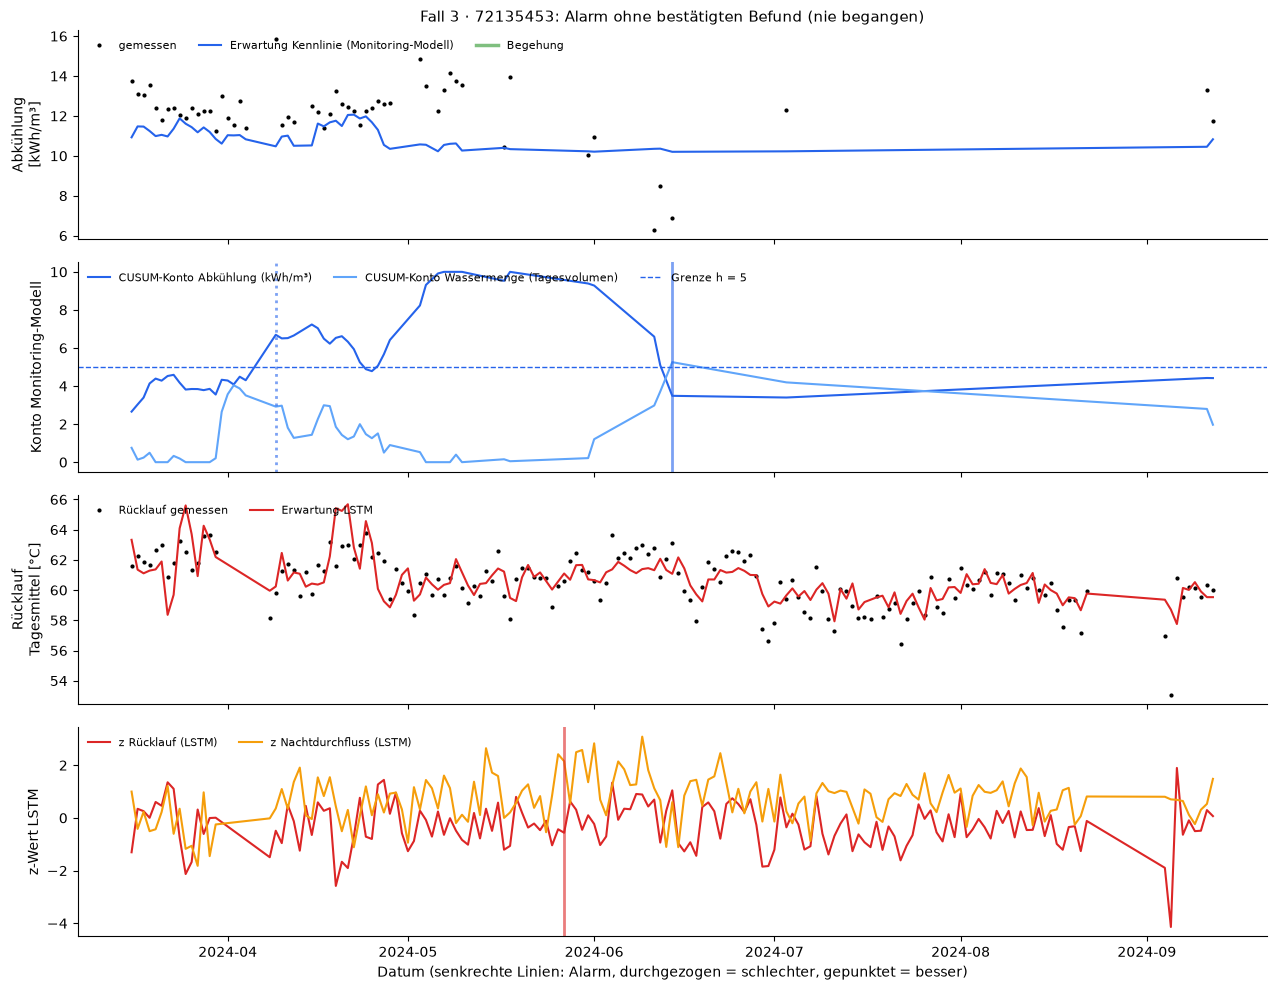

In [49]:
nie = [m for m in w["kal"].index if m not in e["labels"].index and m in set(w["ref"].index[w["ref"]["status"] == "ok"])]
al_mm_t = w["alarme"]["monitoring"]
al_mm_t = al_mm_t[(al_mm_t["datum"] >= fv.TEST_START) & al_mm_t["zaehler"].isin(nie) & (al_mm_t["bewertung"] == "schlechter")]
fall3 = int(al_mm_t["zaehler"].value_counts().index[0])
d3 = al_mm_t[al_mm_t["zaehler"] == fall3]["datum"].min()
print(f"Fall 3: nie begangene Station mit den meisten Verschlechterungsalarmen beim Monitoring-Modell im Test: {fall3}")
fig = fv.fallbild(fall3, w, e, d3 - pd.Timedelta(days=90), d3 + pd.Timedelta(days=90), f"Fall 3 · {fall3}: Alarm ohne bestätigten Befund (nie begangen)")
fv.speichere(fig, "12_fall3")
plt.show()

In [50]:
nicht_ok = w["ref"][w["ref"]["status"] != "ok"]
print("Fall 4: Stationen, die der Wächter des Monitoring-Modells mit der gemeinsamen Lernzeit nicht einlernen kann:")
display(nicht_ok[["ref_tage", "ref_spanne_k", "status"]].assign(LSTM_kalibriert=lambda d: d.index.isin(w["kal"].index)))
print("Gründe: zu wenige Heiztage vor dem Lernende, meist weil die Station erst spät Daten liefert.")

Fall 4: Stationen, die der Wächter des Monitoring-Modells mit der gemeinsamen Lernzeit nicht einlernen kann:


,ref_tage,ref_spanne_k,status,LSTM_kalibriert
meter,,,,
58177384,460,24.258333,keine Tage nach der Referenz,False
80912191,0,0.000000,zu wenige Referenztage,False
80912194,0,0.000000,zu wenige Referenztage,False
80912199,3,6.258333,zu wenige Referenztage,False
81019433,0,0.000000,zu wenige Referenztage,False
81050517,0,0.000000,zu wenige Referenztage,False
81062289,0,0.000000,zu wenige Referenztage,False


Gründe: zu wenige Heiztage vor dem Lernende, meist weil die Station erst spät Daten liefert.


### 15.1 Was die Fälle zeigen

- Fall 1 (68956351, Ventil getauscht am 09.09.2024): Treffer für beide.
  - Am Tag der Reparatur fällt der Rücklauf von etwa 78 auf 50 °C, die Abkühlung steigt von etwa 1 auf über 20 kWh/m³. Das Monitoring-Modell meldet zwei Tage später „besser“, das LSTM ebenfalls im September (vorher im Juli und August zweimal „schlechter“).
  - Die Kennlinie des Monitoring-Modells stammt aus der Zeit mit offenem Ventil, danach stehen seine Konten am Deckel. Ohne neue Referenz ist der Wächter hier stumm. Das LSTM passt sich nach etwa einer Woche an.
  - Vor der Reparatur hatten alle die Station vorn: Netzvergleich Rang 1 mit Fehlerbild „ventil“, Sommernacht-Anteil 100 %, XGBoost p(Ventil) = 0,81.
- Fall 2 (Ventilbefund mit kleinstem Ventil-Score, p = 0,10): von beiden übersehen.
  - Das Monitoring-Modell zeigt Fehlerbild „durchfluss_je_kw“, nicht „ventil“. Kennzahlen: 93 % Sommernächte mit Durchfluss, Nachtdurchfluss 46 l/h, Spreizung bei Last 28,6 K.
  - Mögliche Deutung: anderer Ventilfehler oder anderes Ventil. Was die Daten nicht zeigen, findet kein Modell.
- Fall 3 (72135453, nie begangen): Alarm ohne bestätigten Befund.
  - Das Monitoring-Modell meldet im Juni 2024 „schlechter“. Im Übergang zum Sommer gibt es wenige Heiztage, an ihnen fällt die Abkühlung auf 6 bis 8 kWh/m³. Das LSTM bleibt bis auf einen Tag ruhig.
  - Deutung: eher Übergangszeit als Defekt. Deshalb heißt ein Alarm im Dashboard „Veränderung“, nicht „Fehler“.
- Fall 4: 7 Stationen ohne Referenz, weil sie zu spät Daten liefern. Ehrlich ist „noch nicht bewertbar“.

## 16 Entscheidung und Dashboard-Bauplan

- Entscheidung je Aufgabe, Umsetzung im Dashboard (Notebook 40), Herkunft jedes Feldes, Grenzen.

### 16.1 Entscheidung je Aufgabe

| Aufgabe | Modell im Dashboard | wann es gilt | Urteil | Beleg |
|---|---|---|---|---|
| Stationsleistung, Netzeffizienz, dauerhaft schlechter Betrieb | Monitoring-Modell: Netzvergleich je Kernwinter, Potenzial | ab erstem vollständigem Kernwinter | Pilot (beschreibend) | Test D, Fall 1 |
| Veränderung in der Heizperiode, Erfolgskontrolle | Monitoring-Modell: Tagesmonitor, h = 5; Prognose-LSTM als Hinweis für plötzliche Sprünge | Heiztage, ab 60 Heiztagen Referenz | Pilot mit Einschränkungen: Referenz erneuern | Test A, B, Abschnitt 9, Fall 1, 2 |
| Veränderung an warmen Tagen, plötzlicher Durchfluss | LSTM-Modell: Prognose-LSTM auf allen Stationen, CUSUM h = 10 | ganzjährig, Hauptkanal an warmen Tagen; ab etwa 4 Wochen Stundenwerten | Pilot mit Einschränkungen: an Begehungen nicht belegt | Test B, Abschnitt 10 |
| Fehlerart Ventil | LSTM-Modell: Ventil-Score (nur begangene Stationen); Sommernacht-Anteil als Erklärung; „ventil“ des Monitoring-Modells hebt auf „hoch“ | nach einem Winter und einem Sommer Stundenwerte | Pilot: Score ist Rangfolge, keine Wahrscheinlichkeit | Test C, E |
| Dämmung | LSTM-Modell als Hinweis | wie oben | weitere Validierung nötig | Test C, Abschnitt 18 |
| Kapazitätsanpassung | Regel Spitzenlast zum alten Vertrag | Vertrag vor der Maßnahme bekannt | Pilot mit Einschränkungen (9 Fälle) | Test C |
| Regelungsoptimierung (Folie 5 „mittel“) | nicht im Dashboard | – | ungeeignet | Test C |
| Durchfluss, Sollwert, Filter, Regelhysterese | nur als Symptom (z. B. Fehlerbild „unruhig“) | – | als Ursache nicht erkennbar | Test B, C |
| Empfehlung und Reihenfolge | `dashboard_daten.empfehlungen`: hoch = Reparatur mit „ventil“ des Monitoring-Modells, mittel = Reparatur nach Ventil-Score, niedrig = Kapazität, Dämmung, Daten prüfen | – | Pilot; Stufen gesetzt | Test E |
| echte Frühwarnung | – | – | nicht prüfbar | Abschnitt 2 |
| XGBoost, LSTM feste Referenz, Sommer-LSTM | – | – | kein Mehrwert gegenüber dem Einfacheren | Test C, Abschnitt 9, 10 |

- Wo mit Befunden gelernt wird (Fehlerart), nur begangene Stationen. Wo Normalverhalten gelernt wird (Wächter), alle Stationen. Die andere Fassung ist jeweils als Paket gespeichert.
- Heizperiode: Monitoring-Modell, weil es Maßnahmen am deutlichsten bemerkt und im Winter eingebaute Fehler am besten findet.
- Warme Tage: LSTM-Modell, weil nur es dort rechnet und das Wochenmittel bei wenigen Fehlalarmen schlägt.
- Ventil: LSTM-Modell mit dem Fehlerbild des Monitoring-Modells als Bestätigung. Besser als die Sommernacht-Regel ist es nicht belegt.
- Regelungsoptimierung und Frühwarnung: Evidenz reicht nicht, es fehlen Befunde mit klarer Fehlerart und bekanntem Beginn.

### 16.2 Umsetzung nach Aufgabenstellung

| Aufgabe | Umsetzung im Dashboard | Modell | bewusst nicht enthalten |
|---|---|---|---|
| Datenanalyse | Seitenleiste „Netz“, Färbungen „Potenzial“ und „Meldungen“, Hausfenster „Leistung im Netz“ und „Veränderung“ | Monitoring-Modell: Netzvergleich, Tagesmonitor; LSTM an warmen Tagen | Regelhysterese: findet kein Wächter (Test B) |
| Modellentwicklung | Meldungen je Tag aus genau einem Wächter; Verdacht Ventil, Dämmung, Anschluss zu groß | Tagesmonitor an Heiztagen, sonst Prognose-LSTM; LSTM-Fehlerklassen; Regel Spitzenlast | Regelung, Filter, Sollwert, Durchfluss als Ursache (Test C) |
| Visualisierung | Karte auf dem Rohrbaum aus Notebook 35 mit Zeitregler, eine Färbung zur Zeit; Reiter „So funktioniert's“ | Messwerte, Netzvergleich | Einspar-Schätzung: Wirkung nicht gesichert (Test D) |
| Empfehlungssystem | Reiter „Handlungsliste“, Stufen wie in 16.1, innerhalb nach Ventil-Score | LSTM-Fehlerklassen, Fehlerbild des Monitoring-Modells, Regel Spitzenlast | Regelungsoptimierung (Test C); Sortieren nach Alarmen oder Potenzial (Test D, E); Sonderfälle ohne geprüften Score |

Code: `src/dashboard_daten.py` (Pakete anwenden, Empfehlung), `src/dashboard_karte.py` (Karte), `notebooks/dashboard_final.py` (Oberfläche).

### 16.3 Dashboard-Bauplan: welches Feld woher kommt

- Das Dashboard rechnet nichts selbst. `python -m src.dashboard_daten` wendet die drei Pakete an und schreibt nach `outputs/dashboard/`.

| Feld | Quelle | Paket / Funktion | Spalte |
|---|---|---|---|
| Netzeffizienz je Monat | Messwerte | `dashboard_daten.netzeffizienz` | `netzeffizienz.parquet` |
| Karte mit Zeitregler | Notebook 35, beide Wächter | `notebooks/dashboard_final.py`, `src/dashboard_karte.py` | `alarme.parquet`, `stationen.parquet` |
| Rang, Fehlerbild, Potenzial | Monitoring-Modell | `stationsblatt.rechne` | `netz_rang`, `netz_fehlerbild`, `potenzial` |
| Alarm Heizperiode | Monitoring-Modell | Paket `normalmodell` (dieses Notebook) | `alarme.parquet`, `tm_verschlechterung` |
| Referenz veraltet (Konto am Deckel) | Monitoring-Modell | `dashboard_daten.rechne` | `tm_deckel_anteil` |
| Alarm warme Tage | LSTM-Modell | Paket `prognose_lstm` (dieses Notebook, CUSUM h = 10) | `alarme.parquet`, `lstm_alarme_aktuell` |
| bewertbar, mit Grund | beide | Status der Pakete | `tm_status`, `lstm_status` |
| Ventil-Score, Klasse, Hinweise | LSTM-Modell | Paket `fehlerklassen` (dieses Notebook) | `p_ventil`, `klasse`, `hinweis_daemmung`, `hinweis_vertrag` |
| Symptom | Netzvergleich, Sommernächte | `dashboard_daten.wissensstand` | `symptom` |
| Veränderung | beide Wächter | `wissensstand` | `veraenderung` |
| vermutete Ursache | LSTM-Modell, Regel | `wissensstand` | `vermutete_ursache` |
| dokumentierter Befund | Begehungsprotokoll | `wissensstand` | `befund` |
| Prüfung, Dringlichkeit, Rang | Regeln | `dashboard_daten.empfehlungen` | `handlung`, `dringlichkeit`, `rang` |
| Modellversion | Pakete | `meta.json` | `pakete` |

- „Keine Meldung“ heißt nie „in Ordnung“. Ein Score ist keine Wahrscheinlichkeit.
- Symptom, Vermutung und Befund stehen getrennt. Fehlt eine Voraussetzung, steht „nicht bewertbar“ mit Grund da.

### 16.4 Grenzen

- Wenige Fälle: 43 Begehungen im Test, 11 Ventil- und 9 Vertragsfälle. Unterschiede unter etwa 0,1 AUC oder 5 Fällen sind nicht sichtbar. „Nicht gesichert“ heißt: Daten reichen nicht.
- Viele Gegenproben (sieben Wächter, drei Richtungen, zwei Vergleichsgruppen): Einzelne kleine p-Werte können Zufall sein. Entscheidend ist das gleiche Bild über Test A, B und die Kurven.
- Labels gelten nur für begangene Stationen. Fehlerbeginn unbekannt, 37 nie begangene Stationen sind unbekannt, nicht gesund.
- Feste Referenz beim Monitoring-Modell: An 43 % der Testtage steht ein Konto am Deckel, bei 31 von 81 Stationen mehr als die Hälfte der Zeit.
- Eingebaute Fehler zeigen, was ein Wächter grundsätzlich kann, nicht seine Trefferquote bei echten Fehlern.
- Kleine Probezeit (2.184 Stationstage): Arbeitslasten im Test 2,7 bis 6,4 Alarme je Station und Jahr. Die Rangfolge hängt laut Kurven kaum davon ab.

### 16.5 Warum andere Zahlen als in Notebook 38 und im Audit

| | Notebook 38 | frühere Prüfung (Audit) | hier |
|---|---|---|---|
| Schwellen | auf den Testfällen | Probezeit, 2 Alarme je Jahr | Probezeit April/Mai, Bezug h = 5 des Monitoring-Modells |
| Referenz Monitoring-Modell | eigene Regel (endet kurz vor Begehung) | Kennlinie bis 31.01.2024, ohne Streuungsvergrößerung | Kennlinie bis 31.01.2024, mit ihrer Streuungsregel |
| LSTM-Encoder | sah die Teststationen | je Fold neu, begangene Lernstationen | je Fold neu, nur begangene; Gegenprobe alle |
| Merkmal Auslastung | dabei | entfernt | entfernt |
| Begehungen | alle Alarme zusammen: Monitoring-Modell 33/43 | 27 Begehungen, je 6 mit Alarm vorher und nachher | nach Richtung, Monitoring-Modell 18/43 (besser) |

### 16.6 Kleinster nächster Schritt

1. Referenz erneuern: die Kennlinie des Monitoring-Modells nach jeder Begehung und zu jeder Heizperiode neu lernen (letzte 12 Monate ohne Begehung), dann Test A und B wiederholen.
2. Ventil prospektiv prüfen: nie begangene Stationen mit hohem Ventil-Score und Fehlerbild „ventil“ gezielt begehen.
3. Ursachen statt Symptome: mit der ÜZ abgestimmte Fehler-Symptom-Matrix (Notebook 33) und je Befund der geschätzte Beginn.

### 16.7 Selbstprüfung

- Beide Modelle aus Notebook 00 (Prüfzelle Abschnitt 4), Labels bis zur Quelle (Notebook 27, Protokoll, Teamangabe).
- Stationen und Fenster getrennt gezählt, Unsicherheit über Stationen. Nur vergleichbare Aufgaben verglichen.
- Fairness der Bauweise geprüft (Abschnitt 9, 10, nur begangene). Testdaten aus Lernen und Einstellen heraus (`assert`).
- Generalisierung geprüft: spätere Zeit, neue Stationen, Jahreszeiten. „Wie gebaut“-Fassungen als Gegenprobe gekennzeichnet.

## 17 Modelle speichern und Dashboard umstellen

- Gespeichert wird genau das oben Geprüfte, im Format, das `src/dashboard_daten.py` liest: Gewichte oder Kennlinien, Skalierung, Kalibrierung, Schwelle, Lernzeitraum, Code-Stand, Prüfsummen.
- Alte Versionen bleiben, zurück mit `mp.setze_aktuell(name, version)`. `models/` ist gitignored.

In [51]:
from datetime import datetime
VERSION = "nb34_" + datetime.now().strftime("%Y-%m-%d_%H%M%S")
regel_lstm, wert_lstm = w["einstellung"]["lstm_c"]
datenstand = e["stunden"]["timestamp"].max()
pk_normal = fv.paket_normalmodell(w["ref"], w["mod"], w["modtab"], VERSION,
    kennzahlen={"stationen": int(len(w["ref"])), "ueberwacht": int((w["ref"]["status"] == "ok").sum()),
                "testA_besser": f"{int(A_besser.iloc[0]['bemerkt'])}/{int(A_besser.iloc[0]['Fälle'])}"},
    lernzeitraum=f"Heiztage bis {fv.LERN_ENDE - pd.Timedelta(days=1):%d.%m.%Y} (spätestens 14 Tage vor der ersten Begehung)",
    datenstand=fv.LERN_ENDE)
pk_lstm = fv.paket_prognose(w["lstm"], w["kal"], w["faktor"], regel_lstm, w["einstellung"]["lstm_s"][1], wert_lstm, VERSION,
    kennzahlen={"lern_ziele": w["lstm"]["lern_ziele"], "kalibrierte_stationen": int(len(w["kal"]))},
    datenstand=fv.VAL_ENDE)
pk_fk = fv.paket_fehlerklassen(teile["netz"], teile["skalierung"], teile["ventil_modell"], teile["daemmung_modell"],
    teile["kmeans"], teile["lernbereich"], teile["kreuzvalidierung"], teile["parameter"], VERSION,
    kennzahlen={"ventil_auc_oof": round(float(tab_ventil.set_index("Kandidat").loc[fv.ENDMODELL, "AUC"]), 3),
                "daemmung_auc_oof": round(float(tab_daemmung.set_index("Kandidat").loc[fv.ENDMODELL, "AUC"]), 3),
                "lernstationen": int(len(KL["basis"]))},
    datenstand=fv.STICHTAG)
#die jeweils andere Fassung als Paket zum Umschalten, nicht aktiv
VERSION_ALT = VERSION.replace("nb34_", "nb34gegenprobe_")
regel_b, wert_b = w["einstellung"]["lstm_beg"]
pk_lstm_beg = fv.paket_prognose(w["beg"]["lstm"], w["beg"]["kal"], w["beg"]["faktor"], regel_b, w["einstellung"]["lstm_s"][1], wert_b,
    VERSION_ALT, kennzahlen={"fassung": "nur begangene Stationen gelernt", "lern_ziele": w["beg"]["lstm"]["lern_ziele"]},
    datenstand=fv.VAL_ENDE)
teile_alle = fv.fehlerklassen_teile(KL_alle)
pk_fk_alle = fv.paket_fehlerklassen(teile_alle["netz"], teile_alle["skalierung"], teile_alle["ventil_modell"],
    teile_alle["daemmung_modell"], teile_alle["kmeans"], teile_alle["lernbereich"], teile_alle["kreuzvalidierung"],
    teile_alle["parameter"], VERSION_ALT, kennzahlen={"fassung": "Encoder auf allen Stationen gelernt"}, datenstand=fv.STICHTAG)
for p in (pk_normal, pk_lstm, pk_fk, pk_lstm_beg, pk_fk_alle):
    print(f"{p.name:15s} {p.version:38s} {len(p.meta['dateien'])} Dateien  ->  {p.ordner.relative_to(ROOT)}")

normalmodell    nb34_2026-11-18_154258                 3 Dateien  ->  models/normalmodell/nb34_2026-11-18_154258
prognose_lstm   nb34_2026-11-18_154258                 6 Dateien  ->  models/prognose_lstm/nb34_2026-11-18_154258
fehlerklassen   nb34_2026-11-18_154258                 8 Dateien  ->  models/fehlerklassen/nb34_2026-11-18_154258
prognose_lstm   nb34gegenprobe_2026-11-18_154258       6 Dateien  ->  models/prognose_lstm/nb34gegenprobe_2026-11-18_154258
fehlerklassen   nb34gegenprobe_2026-11-18_154258       8 Dateien  ->  models/fehlerklassen/nb34gegenprobe_2026-11-18_154258


- Gegenprobe: Die geladenen Pakete liefern dieselben Werte wie im Speicher.

In [52]:
from src import normalmodell_waechter as nw
g_lstm = pw.lade(VERSION)
pr = pw.anwenden(g_lstm, e["stunden"], ab=fv.VAL_START)
m = pr.merge(w["z"], on=["zaehler", "tag"], suffixes=("_paket", "_nb"))
print("LSTM-Paket: max. Unterschied z Rücklauf", float((m["z_rl_paket"] - m["z_rl_nb"]).abs().max()))
g_norm = nw.lade(VERSION)
nm = nw.anwenden(g_norm, e["serien"], e["temp"])
print("Normalmodell-Paket: Alarme", len(nm["alarme"]), "gegen", len(fv.monitoring_alarme(w["verlauf"])), "im Notebook")
g_fk = fk.lade(VERSION)
bew = fk.bewerten(g_fk, KL["kz"], KL["final"]["embedding"], oof=g_fk["kreuzvalidierung"])
print("Fehlerklassen-Paket: Klassen", bew["klasse"].value_counts().to_dict())
assert float((m["z_rl_paket"] - m["z_rl_nb"]).abs().max()) < 1e-3
assert len(nm["alarme"]) == len(fv.monitoring_alarme(w["verlauf"]))

LSTM-Paket: max. Unterschied z Rücklauf 1.5172671208318889e-06


Normalmodell-Paket: Alarme 313 gegen 313 im Notebook
Fehlerklassen-Paket: Klassen {'kein Handlungsbedarf': 61, 'Regelventil tauschen': 25, 'Regelparameter optimieren': 4, 'nicht einstufbar': 1}


- Die drei Hauptpakete werden Betriebsversion: `normalmodell` (Wächter des Monitoring-Modells), `prognose_lstm` (alle Stationen), `fehlerklassen` (nur begangene Stationen).
- Die Gegenproben (`nb34gegenprobe_...`) liegen daneben, umschalten mit `mp.setze_aktuell("prognose_lstm", VERSION_ALT)`. Das Dashboard rechnet mit der aktiven Version.

In [53]:
UMSTELLEN = True
vorher = {n: mp.aktuelle_version(n) for n in ("normalmodell", "prognose_lstm", "fehlerklassen")}
if UMSTELLEN:
    for n in vorher:
        mp.setze_aktuell(n, VERSION)
print("Gegenproben zum Umschalten:", VERSION_ALT, "(prognose_lstm: nur begangene, fehlerklassen: alle Stationen)")
pd.DataFrame({"vorher": vorher, "jetzt": {n: mp.aktuelle_version(n) for n in vorher}})

Gegenproben zum Umschalten: nb34gegenprobe_2026-11-18_154258 (prognose_lstm: nur begangene, fehlerklassen: alle Stationen)


,vorher,jetzt
normalmodell,nb34_2026-10-27_121626,nb34_2026-11-18_154258
prognose_lstm,nb34_2026-10-27_121626,nb34_2026-11-18_154258
fehlerklassen,nb34_2026-10-27_121626,nb34_2026-11-18_154258


In [54]:
aus = fv.AUSGABE
aus.mkdir(parents=True, exist_ok=True)
A.to_csv(aus / "testA_begehungen.csv", index=False)
KA.to_csv(aus / "testA_kurve.csv", index=False)
SA.to_csv(aus / "testB_faelle.csv", index=False)
SK.to_csv(aus / "testB_kurve.csv", index=False)
KL["oof"].to_csv(aus / "testC_vorhersagen.csv", index=False)
pd.concat([tab_ventil.assign(Ziel="ventil"), tab_daemmung.assign(Ziel="daemmung"), tab_ueber.assign(Ziel="ueberdimensioniert")]).to_csv(
    aus / "testC_kennzahlen.csv", index=False)
stab.to_csv(aus / "testC_stabilitaet.csv", index=False)
vergleich_beg.to_csv(aus / "testC_nur_begangene_gegen_alle.csv", index=False)
vergleich_nv.to_csv(aus / "test_nv_lstm_feste_referenz.csv")
som["kurve"].to_csv(aus / "test_sommer_lstm.csv", index=False)
gp.to_csv(aus / "testC_gegenprobe.csv")
wp.to_csv(aus / "testD_potenzial.csv")
last.to_csv(aus / "arbeitslast.csv", index=False)
bewertbar.to_csv(aus / "ab_wann_bewertbar.csv", index=False)
print("Ergebnisse in", aus.relative_to(ROOT), ":", sorted(p.name for p in aus.glob("*.csv")))

Ergebnisse in outputs/finalvergleich : ['ab_wann_bewertbar.csv', 'arbeitslast.csv', 'testA_begehungen.csv', 'testA_kurve.csv', 'testB_faelle.csv', 'testB_kurve.csv', 'testC_gegenprobe.csv', 'testC_kennzahlen.csv', 'testC_nur_begangene_gegen_alle.csv', 'testC_stabilitaet.csv', 'testC_vorhersagen.csv', 'testD_potenzial.csv', 'test_nv_lstm_feste_referenz.csv', 'test_sommer_lstm.csv']


## 18 Mehrwert der KI gegenüber Regeln

- Frage: Findet die KI Muster, die eine Regel nicht findet? Fair ist das erst, wenn auch die Regel an den Befunden eingestellt wird.
- Drei Gegenproben auf denselben 53 Stationen und Folds wie Test C:
  1. KI gegen angepasste Regel: je Lernteil die eine Kennzahl samt Richtung, die die Befunde am besten trennt (`fv.regel_angepasst`).
  2. Gleiche Methode, andere Kennzahlen: Regression auf den 5 Winterkennzahlen des Monitoring-Modells und auf Teilmengen der 12 Kennzahlen (`fv.merkmalssaetze_vergleich`).
  3. Wächter zusammen: Kennlinie und Prognose-LSTM auf eingebauten Winterfehlern, Meldung wenn einer meldet (`fv.waechter_zusammen`).
- Die Zellen lesen Test B und C aus `outputs/finalvergleich/`.

In [55]:
oof15 = pd.read_csv(fv.AUSGABE / "testC_vorhersagen.csv")
kz15 = fv.kennzahlen_vor_begehung(e["stunden"], e["labels"])
ziele15 = ["ventil", "daemmung", "ueberdimensioniert", "filter", "durchfluss", "temperatur"]
regel15 = fv.regel_angepasst(kz15, oof15, ziele15)
kg = fv.ki_gegen_regel(oof15, regel15, e["gruppen"], ziele15)
kg.round(2)

,Fehlerart,Befunde,Stationen,Regel angepasst,LR Kennzahlen,KI,KI − Regel,unten,oben,KI vorn in,gesichert,Regel nutzt
0,ventil,11,53,0.79,0.82,0.83,0.04,-0.17,0.23,0.65,False,sommer_nachtfluss_lph (groß = Befund)
1,daemmung,22,53,0.61,0.73,0.79,0.18,-0.03,0.39,0.96,False,"ruecklauf_lastgewichtet (klein = Befund), somm..."
2,ueberdimensioniert,9,35,0.65,0.39,0.49,-0.16,-0.44,0.12,0.13,False,"streubreite_betriebspunkte (groß = Befund), wi..."
3,filter,25,53,0.47,0.43,0.31,-0.16,-0.31,-0.02,0.01,True,"ruecklauf_lastgewichtet (groß = Befund), winte..."
4,durchfluss,18,53,0.38,0.32,0.36,-0.02,-0.20,0.17,0.42,False,"sommer_durchlauf_anteil (klein = Befund), somm..."
5,temperatur,33,53,0.51,0.38,0.30,-0.21,-0.40,-0.03,0.01,True,"winter_fluss_cv (groß = Befund), winter_rueckl..."


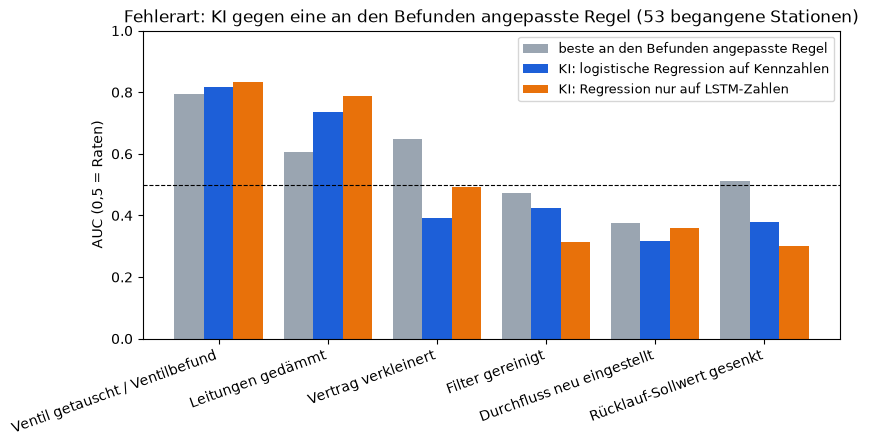

In [56]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(kg))
ax.bar(x - 0.27, kg["Regel angepasst"], 0.27, color="#9aa5b1", label="beste an den Befunden angepasste Regel")
ax.bar(x, kg["LR Kennzahlen"], 0.27, color="#1d5fd8", label="KI: logistische Regression auf Kennzahlen")
ax.bar(x + 0.27, kg["KI"], 0.27, color="#e8710a", label="KI: Regression nur auf LSTM-Zahlen")
ax.axhline(0.5, color="k", lw=0.8, ls="--")
ax.set_xticks(x, [fv.ZIEL_TEXT.get(z, z) for z in kg["Fehlerart"]], rotation=20, ha="right")
ax.set_ylim(0, 1)
ax.set_ylabel("AUC (0,5 = Raten)")
ax.set_title("Fehlerart: KI gegen eine an den Befunden angepasste Regel (53 begangene Stationen)")
ax.legend(loc="upper right", fontsize=9)
fv.speichere(fig, "13_ki_gegen_regel")
plt.show()

### 18.1 KI gegen angepasste Regel

- Dämmung: beste Einzelregel 0,61, Regression auf Kennzahlen 0,73, Dashboard-Modell 0,79. KI vorn um 0,18 [−0,03; +0,39], in 96 % der Ziehungen, knapp nicht gesichert. Das Muster steckt in der Kombination mehrerer Größen.
- Ventil: angepasste Regel (Nachtdurchfluss im Sommer) 0,79, KI 0,83 (+0,04, in 65 % vorn, nicht gesichert). Die feste Sommernacht-Regel (0,85) ist besser als die angepasste: Fachwissen schlägt Anpassen an 11 Fälle.
- Anschluss zu groß: KI scheitert (0,49), ihr fehlt die Auslastung zum alten Vertrag. Die Regel aus Test C (0,76) bleibt.
- Filter, Durchfluss, Temperatur: weder Regel noch KI über 0,51. Die Information steckt nicht in den Zählerwerten.

In [57]:
netz15 = fv.netzvergleich(e["serien"], e["termine"], e["anschluss"], e["bhkw"])
mm15 = fv.monitoring_kennzahlen(netz15, "23/24").add_prefix("iv_")
sommer15 = ["sommer_nachtfluss_lph", "sommer_durchlauf_anteil", "sommer_nacht_spreizung_k", "sommerlast_anteil"]
winter15 = [k for k in fv.KENNZAHLEN if k not in sommer15]
X15 = kz15[fv.KENNZAHLEN].join(mm15)
saetze15 = {"LR 5 Winterkennzahlen des Monitoring-Modells": list(mm15.columns),
            "LR 8 Winterkennzahlen (Modell-Strang)": winter15,
            "LR 4 Sommerkennzahlen (Modell-Strang)": sommer15,
            "LR alle 12 Kennzahlen (Modell-Strang)": list(fv.KENNZAHLEN),
            "LR 12 + 5 des Monitoring-Modells": list(fv.KENNZAHLEN) + list(mm15.columns)}
ms = fv.merkmalssaetze_vergleich(X15, oof15, e["gruppen"], saetze15, ["ventil", "daemmung"])
ms[["Fehlerart", "Kennzahlen", "Anzahl", "AUC", "gefunden", "übersehen", "Fehlalarm"]].round(2)

,Fehlerart,Kennzahlen,Anzahl,AUC,gefunden,übersehen,Fehlalarm
0,ventil,LR 5 Winterkennzahlen des Monitoring-Modells,5,0.65,5,6,11
1,ventil,LR 8 Winterkennzahlen (Modell-Strang),8,0.74,6,5,10
2,ventil,LR 4 Sommerkennzahlen (Modell-Strang),4,0.92,8,3,3
3,ventil,LR alle 12 Kennzahlen (Modell-Strang),12,0.82,8,3,5
4,ventil,LR 12 + 5 des Monitoring-Modells,17,0.82,9,2,6
5,daemmung,LR 5 Winterkennzahlen des Monitoring-Modells,5,0.60,12,10,12
6,daemmung,LR 8 Winterkennzahlen (Modell-Strang),8,0.73,13,9,10
7,daemmung,LR 4 Sommerkennzahlen (Modell-Strang),4,0.57,10,12,9
8,daemmung,LR alle 12 Kennzahlen (Modell-Strang),12,0.73,14,8,7
9,daemmung,LR 12 + 5 des Monitoring-Modells,17,0.76,14,8,7


### 18.2 Gleiche Methode, andere Kennzahlen

- Ventil: Die Sommerkennzahlen entscheiden (Winter 0,65 bis 0,74, 4 Sommerkennzahlen 0,92). Auf den Kennzahlen des Monitoring-Modells ist die Regression (0,65) nicht besser als dessen feste Regel (0,73). Der Vorsprung kommt davon, was gemessen wird, nicht vom Lernen.
- Dämmung: Winterkennzahlen tragen (0,73), Sommer allein nicht (0,57). Hier hilft Lernen auch auf den Kennzahlen des Monitoring-Modells (0,60 gegen 0,38).
- Mehr Kennzahlen sind nicht automatisch besser: Beim Ventil verwässern Winterkennzahlen das Sommersignal (0,82 gegen 0,92).
- Die Sätze wurden nachträglich auf denselben 53 Stationen verglichen. 0,92 ist ein Hinweis, kein geprüfter Wert. Belastbar ist die Richtung (Vorarbeit 0,91, Lernpfad 0,88, Sommernacht-Regel 0,85).

In [58]:
faelle15 = pd.read_csv(fv.AUSGABE / "testB_faelle.csv")
wz = fv.waechter_zusammen(faelle15, "monitoring", "lstm_c", "Winter")
anzeige = wz.rename(columns={"monitoring": "Monitoring %", "lstm_c": "Prognose-LSTM %", "zusammen": "zusammen %"})
anzeige[["Monitoring %", "Prognose-LSTM %", "zusammen %"]] *= 100
anzeige.round(0)

key,Monitoring %,Prognose-LSTM %,zusammen %,Fälle
art,,,,
Dauerdurchfluss 150 l/h,78.0,69.0,87.0,77
Dauerdurchfluss 50 l/h,57.0,45.0,70.0,77
Fühler hängt,48.0,27.0,61.0,77
Regelhysterese 6 h,13.0,10.0,22.0,77
Rücklauf +5 K,56.0,25.0,65.0,77
ohne Fehler,12.0,3.0,12.0,77
schleichend +5 K in 30 Tagen,53.0,18.0,56.0,78


### 18.3 Wächter zusammen

- Im Winter ergänzt das Prognose-LSTM vor allem plötzliche Fehler: Dauerdurchfluss 50 l/h 57 auf 70 %, Fühler hängt 48 auf 61 %, Rücklauf +5 K 56 auf 65 %. Bei langsamen Fehlern kaum (53 auf 56 %). Über alle von 51 auf 60 %.
- Fehlalarme bleiben bei 12 %, weil die LSTM-Fehlalarme in dieselben Fenster fallen.
- Nur an eingebauten Fehlern gemessen. An echten Begehungen (Test A) meldet das LSTM nicht öfter als an Vergleichsstationen.

In [59]:
kg.to_csv(fv.AUSGABE / "ki_gegen_regel.csv", index=False)
regel15.to_csv(fv.AUSGABE / "ki_gegen_regel_vorhersagen.csv", index=False)
ms.to_csv(fv.AUSGABE / "kennzahlen_saetze.csv", index=False)
wz.to_csv(fv.AUSGABE / "waechter_zusammen.csv")
print("gespeichert in", fv.AUSGABE)

gespeichert in /home/dom/Code/Github Projekt/dominik-abgabe/outputs/finalvergleich


### 18.4 Was Abschnitt 18 heißt

- Die KI hat Mehrwert, wo eine Regel nicht reicht: Dämmung (Muster aus mehreren Kennzahlen, knapp nicht gesichert) und Wächter für plötzliche Sprünge (an eingebauten Fehlern, ohne zusätzliche Fehlalarme). Beim Ventil ist eine Regel genauso gut.
- Am Dashboard ändert sich nichts: Dämmung bleibt Hinweis mit niedriger Dringlichkeit (physikalisch ungeklärt). LSTM-Meldungen an Heiztagen bleiben Hinweis im Hausfenster. Der Reiter „So funktioniert's“ nennt beides.
- Sechs Fehlerarten und fünf Kennzahlensätze: Einzelne knappe Ergebnisse können Zufall sein.

## 19 Modellwahl ohne Blick auf die Testdaten

- In Test C wurde jeder Kandidat sauber bewertet, gewählt wurde der Sieger (0,88) aber nach genau diesen Testwerten. Damit ist seine Zahl zu optimistisch.
- Hier passiert auch die Wahl nur auf den Lernstationen (`fv.modellwahl_verschachtelt`), gleiche Folds und Startwerte wie Test C:
  1. LSTM-Fingerabdruck ohne Teststationen neu lernen.
  2. Jeden der fünf Kandidaten mit innerer Kreuzvalidierung (4 Teile über Stationsgruppen) nur im Lernteil bewerten.
  3. Den besten auf allen Lernstationen lernen und einmal auf die Teststationen anwenden. Bei Gleichstand gewinnt der einfachere.
- Gerechnet für Ventil und Dämmung.

In [60]:
oof16 = pd.read_csv(fv.AUSGABE / "testC_vorhersagen.csv")
mw = fv.modellwahl_verschachtelt(e, oof16, ["ventil", "daemmung"], log=print)
mw["wahl"].pivot(index="fold", columns="ziel", values="gewaehlt")

LSTM-Encoder: 88 Runden, bester Validierungsfehler 0.1708, 8 s


Durchgang 1 von 5 fertig


LSTM-Encoder: 85 Runden, bester Validierungsfehler 0.1617, 7 s


Durchgang 2 von 5 fertig


LSTM-Encoder: 87 Runden, bester Validierungsfehler 0.1935, 8 s


Durchgang 3 von 5 fertig


LSTM-Encoder: 73 Runden, bester Validierungsfehler 0.1845, 6 s


Durchgang 4 von 5 fertig


LSTM-Encoder: 84 Runden, bester Validierungsfehler 0.1374, 8 s


Durchgang 5 von 5 fertig


ziel,daemmung,ventil
fold,,
0,XGBoost Kennzahlen + LSTM,XGBoost Kennzahlen + LSTM
1,LR nur LSTM-Embedding,LR Kennzahlen + LSTM
2,LR Kennzahlen + LSTM,LR nur LSTM-Embedding
3,LR nur LSTM-Embedding,LR nur LSTM-Embedding
4,LR nur LSTM-Embedding,XGBoost Kennzahlen + LSTM


In [61]:
innen16 = mw["wahl"].set_index(["ziel", "fold"]).drop(columns="gewaehlt")
innen16.columns = [c.replace("AUC im Lernteil: ", "") for c in innen16.columns]
innen16.round(2)

,,LR Kennzahlen,LR Kennzahlen + LSTM,LR nur LSTM-Embedding,XGBoost Kennzahlen,XGBoost Kennzahlen + LSTM
ziel,fold,,,,,
ventil,0,0.81,0.86,0.91,0.66,0.94
daemmung,0,0.75,0.81,0.79,0.70,0.87
ventil,1,0.85,0.87,0.82,0.83,0.81
daemmung,1,0.66,0.76,0.79,0.60,0.73
ventil,2,0.73,0.81,0.82,0.71,0.72
daemmung,2,0.68,0.81,0.77,0.68,0.75
ventil,3,0.76,0.82,0.84,0.66,0.68
daemmung,3,0.61,0.68,0.71,0.59,0.60
ventil,4,0.84,0.85,0.81,0.77,0.88


- Der Sieger wechselt je Durchgang. Ventil: zweimal XGBoost mit LSTM, zweimal Regression nur auf LSTM, einmal Regression auf Kennzahlen + LSTM. Dämmung: dreimal Regression nur auf LSTM.
- In jedem Durchgang gewinnt ein Kandidat mit LSTM-Zahlen, nie Kennzahlen allein. Die Abstände sind oft nur wenige Hundertstel.

In [62]:
vgl16 = mw["oof"].merge(oof16[oof16["kandidat"] == fv.ENDMODELL][["zaehler", "ziel", "p"]]
                        .rename(columns={"p": "p_test_c"}), on=["zaehler", "ziel"])
abw16 = (vgl16["p_fest_nachgerechnet"] - vgl16["p_test_c"]).abs()
print(f"Abgleich mit Test C (feste Wahl {fv.ENDMODELL}, gleiche Folds und Startwerte):",
      f"größte Abweichung {abw16.max():.4f}, mittlere {abw16.mean():.4f}")

Abgleich mit Test C (feste Wahl LR nur LSTM-Embedding, gleiche Folds und Startwerte): größte Abweichung 0.0000, mittlere 0.0000


- Die feste Wahl aus Test C wird genau nachgerechnet (Abweichung 0). Unterschiede unten kommen nur von der Modellwahl.

In [63]:
tab16 = fv.modellwahl_auswerten(mw, oof16, e["gruppen"])
tab16.round(2)

,Fehlerart,Verfahren,AUC,unten,oben,gefunden,übersehen,Fehlalarm,Befunde unter den ersten 10,gegen feste Wahl,Diff. unten,Diff. oben
0,ventil,Modellwahl im Lernteil (verschachtelt),0.84,0.68,0.97,8,3,5,8,0.00,-0.08,0.10
1,ventil,"LR nur LSTM-Embedding, fest gewählt (Test C)",0.83,0.64,0.98,8,3,4,7,NaN,NaN,NaN
2,ventil,Regel Sommernacht-Anteil (ohne Lernen),0.85,0.68,0.98,9,2,5,7,NaN,NaN,NaN
3,daemmung,Modellwahl im Lernteil (verschachtelt),0.78,0.64,0.91,15,7,6,9,-0.01,-0.10,0.09
4,daemmung,"LR nur LSTM-Embedding, fest gewählt (Test C)",0.79,0.65,0.90,15,7,7,9,NaN,NaN,NaN


- Ventil: mit Wahl im Lernteil 0,84 [0,68; 0,97], 8 von 11 bei 5 Fehlalarmen, 8 unter den ersten 10. Dashboard-Modell allein 0,83 (Unterschied +0,00 [−0,08; +0,10]). Die zuerst gewählte 0,88 war um etwa 0,05 zu optimistisch. Gleichauf mit der Sommernacht-Regel (0,85; −0,01 [−0,14; +0,12]).
- Dämmung: 0,78 [0,64; 0,91], Dashboard-Modell allein 0,79 (−0,01 [−0,10; +0,09]). Gegen die beste angepasste Regel (0,61) +0,17 [−0,04; +0,38], in 95 % vorn, knapp nicht gesichert.
- Für Aussagen gelten ab jetzt diese Zahlen: Ventil 0,84, Dämmung 0,78.

In [64]:
mw["oof"].to_csv(fv.AUSGABE / "modellwahl_verschachtelt_vorhersagen.csv", index=False)
mw["wahl"].to_csv(fv.AUSGABE / "modellwahl_verschachtelt_wahl.csv", index=False)
tab16.to_csv(fv.AUSGABE / "modellwahl_verschachtelt.csv", index=False)
print("gespeichert in", fv.AUSGABE)

gespeichert in /home/dom/Code/Github Projekt/dominik-abgabe/outputs/finalvergleich


### 19.1 Was das heißt

- Beim Ventil ist die KI gleichauf mit der einfachen Regel. Bei der Dämmung findet nur die KI ein Muster (0,78 gegen 0,61), knapp nicht gesichert.
- Welcher Kandidat mit LSTM-Zahlen gewinnt, hängt an wenigen Hundertstel. Das Dashboard nimmt den einfachsten, die Regression nur auf LSTM-Zahlen (19.3). Begründung im Hausfenster bleibt die Sommernacht-Regel.

### 19.2 Alle fünf Fehlerarten gegen die Regeln

- Modellwahl im Lernteil auch für Filter, Durchfluss und Sollwert. Danach alle fünf Fehlerarten gegen die angepasste Regel aus Abschnitt 18, gleiche Stationen, Folds und Ziehungen.
- Beim Ventil zusätzlich gegen die feste Sommernacht-Regel, dort die stärkere Regel.

In [65]:
mw3 = fv.modellwahl_verschachtelt(e, oof16, ["filter", "durchfluss", "temperatur"], log=print)
mw3["wahl"].pivot(index="fold", columns="ziel", values="gewaehlt")

LSTM-Encoder: 88 Runden, bester Validierungsfehler 0.1708, 8 s


Durchgang 1 von 5 fertig


LSTM-Encoder: 85 Runden, bester Validierungsfehler 0.1617, 7 s


Durchgang 2 von 5 fertig


LSTM-Encoder: 87 Runden, bester Validierungsfehler 0.1935, 7 s


Durchgang 3 von 5 fertig


LSTM-Encoder: 73 Runden, bester Validierungsfehler 0.1845, 6 s


Durchgang 4 von 5 fertig


LSTM-Encoder: 84 Runden, bester Validierungsfehler 0.1374, 7 s


Durchgang 5 von 5 fertig


ziel,durchfluss,filter,temperatur
fold,,,
0,XGBoost Kennzahlen + LSTM,LR Kennzahlen,LR Kennzahlen
1,XGBoost Kennzahlen + LSTM,XGBoost Kennzahlen,LR Kennzahlen
2,XGBoost Kennzahlen + LSTM,XGBoost Kennzahlen + LSTM,LR nur LSTM-Embedding
3,XGBoost Kennzahlen,LR nur LSTM-Embedding,XGBoost Kennzahlen
4,LR Kennzahlen,XGBoost Kennzahlen + LSTM,XGBoost Kennzahlen


- Bei Filter, Durchfluss und Sollwert wechselt der Sieger noch stärker, auch Kandidaten ohne LSTM-Zahlen gewinnen. Das passt dazu, dass es dort kein verlässliches Muster gibt.

In [66]:
ziele16 = ["ventil", "daemmung", "filter", "durchfluss", "temperatur"]
kz16 = fv.kennzahlen_vor_begehung(e["stunden"], e["labels"])
regel16 = fv.regel_angepasst(kz16, oof16, ziele16)
verschachtelt = pd.concat([mw["oof"], mw3["oof"]])
ki16 = verschachtelt[["zaehler", "fold", "ziel", "p", "y"]].assign(kandidat="KI mit Modellwahl im Lernteil")
kg16 = fv.ki_gegen_regel(pd.concat([oof16, ki16]), regel16, e["gruppen"], ziele16, ki="KI mit Modellwahl im Lernteil")
kg16 = kg16.rename(columns={"KI": "KI mit Modellwahl im Lernteil"})
kg16[["Fehlerart", "Befunde", "Regel angepasst", "LR Kennzahlen", "KI mit Modellwahl im Lernteil",
      "KI − Regel", "unten", "oben", "KI vorn in", "gesichert"]].round(2)

,Fehlerart,Befunde,Regel angepasst,LR Kennzahlen,KI mit Modellwahl im Lernteil,KI − Regel,unten,oben,KI vorn in,gesichert
0,ventil,11,0.79,0.82,0.84,0.04,-0.11,0.22,0.69,False
1,daemmung,22,0.61,0.73,0.78,0.17,-0.04,0.38,0.95,False
2,filter,25,0.47,0.43,0.39,-0.08,-0.25,0.09,0.18,False
3,durchfluss,18,0.38,0.32,0.37,-0.01,-0.22,0.19,0.45,False
4,temperatur,33,0.51,0.38,0.37,-0.15,-0.36,0.07,0.08,False


In [67]:
v = verschachtelt[verschachtelt["ziel"] == "ventil"].set_index("zaehler")
regel_fest = oof16[(oof16["ziel"] == "ventil") & (oof16["kandidat"] == "Regel Sommernacht-Anteil")].set_index("zaehler")["p"]
d, lo, hi = fv.bootstrap_auc_differenz(v["y"].to_numpy(), v["p"].to_numpy(), regel_fest.reindex(v.index).to_numpy(),
                                       e["gruppen"].reindex(v.index).to_numpy())
print(f"Ventil, KI mit Modellwahl im Lernteil gegen die feste Sommernacht-Regel: {d:+.2f} [{lo:+.2f}; {hi:+.2f}]")

Ventil, KI mit Modellwahl im Lernteil gegen die feste Sommernacht-Regel: -0.01 [-0.14; +0.12]


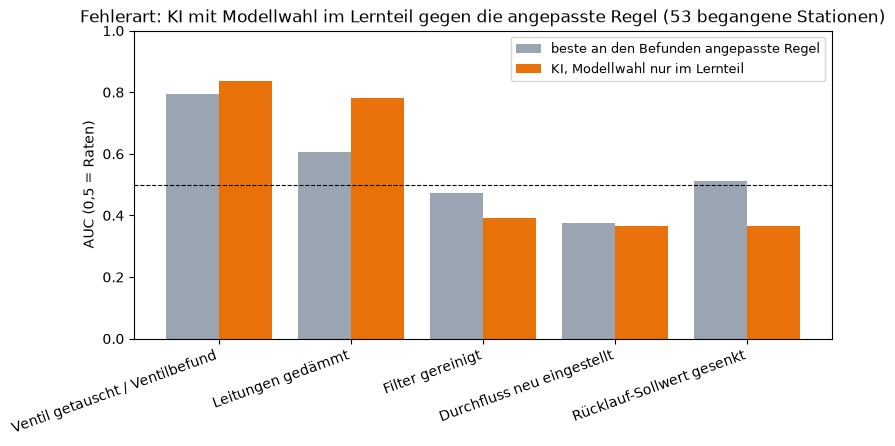

In [68]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(kg16))
ax.bar(x - 0.2, kg16["Regel angepasst"], 0.4, color="#9aa5b1", label="beste an den Befunden angepasste Regel")
ax.bar(x + 0.2, kg16["KI mit Modellwahl im Lernteil"], 0.4, color="#e8710a", label="KI, Modellwahl nur im Lernteil")
ax.axhline(0.5, color="k", lw=0.8, ls="--")
ax.set_xticks(x, [fv.ZIEL_TEXT.get(z, z) for z in kg16["Fehlerart"]], rotation=20, ha="right")
ax.set_ylim(0, 1)
ax.set_ylabel("AUC (0,5 = Raten)")
ax.set_title("Fehlerart: KI mit Modellwahl im Lernteil gegen die angepasste Regel (53 begangene Stationen)")
ax.legend(loc="upper right", fontsize=9)
fv.speichere(fig, "14_ki_gegen_regel_modellwahl")
plt.show()

- Ventil: KI 0,84 gegen angepasste Regel 0,79 (+0,04 [−0,11; +0,22], in 69 % vorn). Gegen die feste Sommernacht-Regel (0,85) gleichauf: −0,01 [−0,14; +0,12].
- Dämmung: KI 0,78 gegen 0,61, +0,17 [−0,04; +0,38], in 95 % vorn, knapp nicht gesichert.
- Filter, Durchfluss, Sollwert: KI 0,39 / 0,37 / 0,37, Regel 0,47 / 0,38 / 0,51. Keiner besser als Raten.
- Die Aussage aus Abschnitt 18 bleibt, nur mit etwas kleineren, sauberen Zahlen.

In [69]:
mw3["oof"].to_csv(fv.AUSGABE / "modellwahl_verschachtelt_weitere_vorhersagen.csv", index=False)
mw3["wahl"].to_csv(fv.AUSGABE / "modellwahl_verschachtelt_weitere_wahl.csv", index=False)
kg16.to_csv(fv.AUSGABE / "ki_gegen_regel_modellwahl.csv", index=False)
print("gespeichert in", fv.AUSGABE)

gespeichert in /home/dom/Code/Github Projekt/dominik-abgabe/outputs/finalvergleich


### 19.3 Welches Modell kommt ins Dashboard?

- Auch diese Wahl schaut nicht auf die Testzahlen, nur auf die Validierung: AUC jedes Kandidaten in den inneren Teilen, gemittelt über die fünf Durchgänge.

In [70]:
wahl16 = pd.concat([mw["wahl"], mw3["wahl"]])
spalten = [c for c in wahl16.columns if c.startswith("AUC im Lernteil")]
innen_mittel = wahl16.groupby("ziel")[spalten].mean().T
innen_mittel.index = [i.replace("AUC im Lernteil: ", "") for i in innen_mittel.index]
innen_mittel[["ventil", "daemmung"]].round(2)

ziel,ventil,daemmung
LR Kennzahlen,0.80,0.67
LR Kennzahlen + LSTM,0.84,0.76
LR nur LSTM-Embedding,0.84,0.77
XGBoost Kennzahlen,0.73,0.63
XGBoost Kennzahlen + LSTM,0.81,0.73


- Ventil: Regression nur auf LSTM-Zahlen und auf Kennzahlen + LSTM gleichauf (beide 0,84). Dämmung ebenfalls (0,77 und 0,76). XGBoost liegt dahinter und schwankt.
- Bei Gleichstand nimmt das Dashboard das einfachere Modell: Regression nur auf den 16 LSTM-Zahlen (`fv.ENDMODELL`). Kennzahlen bleiben Begründung (Sommernacht) und Messlatte.
- Seine Testzahl (Test C): Ventil 0,83, 8 von 11 bei 4 Fehlalarmen; Dämmung 0,79, 15 von 22 bei 7 Fehlalarmen. Nahe am sauberen Verfahren (0,84 und 0,78).
- Preis: Beim Ventil schwankt es mit anderen Startwerten stärker (0,83 bis 0,90 gegen 0,88 bis 0,89), und sein Score sinkt nach einer Begehung auch ohne Ventiltausch (11.8).

## Zusammenfassung & Bewertung

**Ergebnis**
- Keins der beiden Modelle ist allein besser. Das Monitoring-Modell übernimmt Heizperiode, Erfolgskontrolle und Netzvergleich, das LSTM-Modell die warmen Tage und die Fehlerart Ventil (mit dem Fehlerbild des Monitoring-Modells als Bestätigung).
- Test A: Das Monitoring-Modell bemerkt 18 von 43 Begehungen als „besser“ gegen 24 % Kontrolle (p = 0,006). Das Prognose-LSTM liegt auf Höhe der Kontrolle.
- Test B: Im Winter findet das Monitoring-Modell bei 10 % Fehlalarmen am meisten (Rücklauf +5 K 47 % gegen 33 %), im Sommer nur das LSTM (Dauerdurchfluss 150 l/h 78 % bei 5 % Fehlalarmen).
- Fehlerart mit Modellwahl im Lernteil: Ventil 0,84 (Sommernacht-Regel 0,85), Dämmung 0,78 (beste Einzelregel 0,61). Kapazität nur per Regel (0,76).
- Die drei Pakete `normalmodell`, `prognose_lstm`, `fehlerklassen` sind gespeichert, nachgeprüft und Betriebsversion des Dashboards (Notebook 40).

**Belastbar**
- Gleiche Daten, Zeitachse und Alarmlast für alle Wächter, Teststationen nie im Lernen, Unsicherheit über Stationen.
- Der Vorteil des Monitoring-Modells kommt von der festen Referenz: Ein gleich gebautes LSTM ist gleich gut (18 gegen 17 Prozentpunkte Vorsprung).
- Regelungsoptimierung, Durchfluss, Sollwert, Filter und Regelhysterese sind in den Zählerdaten nicht erkennbar.
- XGBoost und ein eigenes Sommer-LSTM bringen keinen Mehrwert.

**Schwach**
- Wenige Fälle: 43 Begehungen, 11 Ventil-, 9 Vertragsfälle. Viele Vorsprünge sind nicht gesichert (Dämmung +0,17 [−0,04; +0,38]).
- Fall für Fall ist der Vorsprung des Monitoring-Modells gegen das LSTM nicht gesichert (p = 0,08 und 0,13). Mit nur begangenen Vergleichsstationen sinkt er (p = 0,17).
- Die Konten des Monitoring-Modells stehen an 43 % der Testtage am Deckel. Der Ventil-Score des Dashboard-Modells sinkt nach jeder Begehung, nicht nur nach Ventiltausch.
- Wirkung der Begehungen auf die Abkühlung (+0,82 kWh/m³) nicht gesichert (p = 0,37). Potenzial sagt die Wirkung kaum vorher.

**Offen**
- Referenz nach jeder Begehung und Heizperiode neu lernen, dann Test A und B wiederholen.
- Prospektiver Test: Stationen mit hohem Ventil-Score und Fehlerbild „ventil“ gezielt begehen.
- Echte Frühwarnung und Regelungsfehler bleiben nicht prüfbar, solange Befunde mit Fehlerbeginn und klarer Fehlerart fehlen (Fehler-Symptom-Matrix, Notebook 33).
- Fall 2 (Ventilbefund mit kleinstem Score) ist nur über seine Kennzahlen beschrieben. Warum beide Modelle ihn übersehen, ist ungeklärt.